In [ ]:
!pip install fasttext

In [ ]:
!pip install tensorflow

In [ ]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import logging
logging.getLogger('absl').setLevel(logging.ERROR)
import ast
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import tensorflow as tf
import fasttext
from sklearn.utils import class_weight
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from tensorflow.keras.preprocessing.text import Tokenizer, tokenizer_from_json
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.regularizers import l2
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.layers import SpatialDropout1D, Input, Embedding, Bidirectional, LSTM, Dense, Dropout, Layer
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

E0000 00:00:1781188315.012959     183 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1781188315.020243     183 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1781188315.037565     183 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781188315.037583     183 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781188315.037586     183 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1781188315.037588     183 computation_placer.cc:177] computation placer already registered. Please check linka

In [ ]:
# 1. Load Data
path_raw = '/kaggle/input/datasets/zalfaintannadhifan/scraping-dataset-raw/dataset 7036.xlsx'

# Membaca file excel
df = pd.read_excel(path_raw)

# Menampilkan 5 data teratas
df.head()
aspects = ['Pelayanan', 'Kamar', 'Fasilitas', 'Makanan', 'Lokasi', 'Suasana', 'Harga']

print(df.head)

<bound method NDFrame.head of        No.                                             Ulasan  Pelayanan  \
0        1  Semuanya menyenangkan, tapi ada yang kurang me...         -1   
1        2  Menginap untuk merayakan ulang tahun ibu saya,...          1   
2        3  Sejauh ini bagus. Kamarnya bersih, nyaman, dan...          1   
3        4  Hotel terbaik untuk keluarga, makanan lezat, d...          0   
4        5  Yang paling berkesan bagi saya adalah keramaha...          1   
...    ...                                                ...        ...   
7031  7032  Jadi, tempatnya strategis yang ada malnya, mud...          0   
7032  7033  Lokasinya strategis. Tapi mungkin pelayanannya...         -1   
7033  7034  Parkir agak jauh dari lobi... sehingga menyuli...          0   
7034  7035  Tempatnya bersih, pelayanannya ramah, lokasiny...          1   
7035  7036                    Suasana ramah justru meningkat.          0   

      Kamar  Fasilitas  Makanan  Lokasi  Suasana  Harga  

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7036 entries, 0 to 7035
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   No.        7036 non-null   int64 
 1   Ulasan     7036 non-null   object
 2   Pelayanan  7036 non-null   int64 
 3   Kamar      7036 non-null   int64 
 4   Fasilitas  7036 non-null   int64 
 5   Makanan    7036 non-null   int64 
 6   Lokasi     7036 non-null   int64 
 7   Suasana    7036 non-null   int64 
 8   Harga      7036 non-null   int64 
dtypes: int64(8), object(1)
memory usage: 494.8+ KB


In [ ]:
print(df.isnull().sum())

No.          0
Ulasan       0
Pelayanan    0
Kamar        0
Fasilitas    0
Makanan      0
Lokasi       0
Suasana      0
Harga        0
dtype: int64


In [ ]:
print("Total duplikat:", df.duplicated().sum())

Total duplikat: 0


In [ ]:
print("===== DATA AWAL =====")
print(df[['Ulasan']].head())

===== DATA AWAL =====
                                              Ulasan
0  Semuanya menyenangkan, tapi ada yang kurang me...
1  Menginap untuk merayakan ulang tahun ibu saya,...
2  Sejauh ini bagus. Kamarnya bersih, nyaman, dan...
3  Hotel terbaik untuk keluarga, makanan lezat, d...
4  Yang paling berkesan bagi saya adalah keramaha...


In [ ]:
# KAMUS NORMALISASI TEKS
# Memetakan kata tidak baku menjadi bentuk baku sesuai KBBI
NORM_DICT = {
    # 1. Kata ganti, preposisi, & singkatan umum
    'yg': 'yang', 'dgn': 'dengan', 'dg':'dengan', 'utk': 'untuk', 'krn': 'karena', 'karna': 'karena', 'krna': 'karena','sdh': 'sudah', 'udh': 'sudah', 'udah': 'sudah', 'bs': 'bisa', 'bsa': 'bisa', 'sy': 'saya', 'aku': 'saya', 'jgn': 'jangan', 'kl': 'kalau', 'klo': 'kalau', 'kalo': 'kalau', 'klu': 'kalau', 'dtg': 'datang', 'lg': 'lagi', 'lgi': 'lagi', 'tp': 'tapi', 'tpi': 'tapi', 'hrs': 'harus', 'msh': 'masih', 'msih': 'masih', 'bgt': 'banget', 'bngt': 'banget', 'bgtt': 'banget',

    # 2. Partikel (dihapus dari kalimat - bukan sentimen)
    'aja': 'saja', 'aj': 'saja', 'deh': '', 'dong': '', 'sih': '', 'mah': '', 'kok': '', 'sich': '', 'doong': '',

    # 3. Kata negasi
    'ga': 'tidak', 'gak': 'tidak', 'ngak': 'tidak', 'nggak': 'tidak', 'ngga': 'tidak', 'gk': 'tidak', 'tak': 'tidak', 'tdk': 'tidak', 'enggak': 'tidak', 'nggk': 'tidak', 'bkn': 'bukan', 'blm': 'belum', 'blum': 'belum', 'blom': 'belum', 'belom': 'belum',

    # 4. Kata tidak baku lainnya
    'emg': 'memang', 'emang': 'memang', 'kayak': 'seperti', 'kyk': 'seperti', 'gimana': 'bagaimana', 'gmn': 'bagaimana', 'gitu': 'begitu', 'gini': 'begini', 'gt': 'begitu', 'abis': 'habis', 'smpe': 'sampai', 'ampe': 'sampai', 'sampe': 'sampai', 'cuma': 'hanya', 'cm': 'hanya', 'krg': 'kurang', 'kurg': 'kurang', 'sgt': 'sangat', 'bener': 'benar', 'bner': 'benar', 'lbh': 'lebih', 'lbih': 'lebih',

    # 5. Kata spesifik domain hotel
    'staffnya': 'staf', 'stafnya': 'staf', 'staffs': 'staf', 'chekout': 'checkout', 'checkin': 'check in', 'ac': 'pendingin ruangan', 'wfi': 'wifi', 'wfe': 'wifi', 'kamarkamarnya': 'kamar', 'kmrnya': 'kamar', 'kamarya': 'kamar', 'kaemar': 'kamar', 'kamarna': 'kamar', 'kmwc' : 'kamar mandi', 'bathroomnya': 'kamar mandi', 'jacuzzinya': 'jacuzzi', 'lifnya': 'lift',

    # 6. Kata Inggris yang sering muncul
    'good': 'bagus', 'nice': 'bagus', 'great': 'bagus', 'best': 'terbaik', 'clean': 'bersih', 'ok': 'oke', 'okay': 'oke', 'overall': 'semua',

    # 7. Kata Lainnya
    'ramahramah': 'ramah', 'enakenak': 'enak', 'enakkkkkkkk': 'enak', 'jelekkk': 'jelek', 'mantaapp': 'mantap', 'toppp': 'top', 'nyamannnnn': 'nyaman', 'bagusbersih': 'bagus bersih', 'bagusbersihmewah': 'bagus bersih mewah', 'terjangkaumurah': 'terjangkau murah', 'makanansarapan': 'makanan sarapan',

    # 8. Token hasil konversi angka (Dari regex)
    'harga_jutaan': 'harga mahal', 'harga_ribuan': 'harga terjangkau',
    'harga_nominal': 'harga',

    # 9. TAMBAHAN TYPO EKSTREM DARI DATASET ULASAN
    'checkinnya': 'check in', 'checkincheckout': 'check in check out', 'checkinout': 'check in check out', 'dicekin': 'check in', 'nunggucheck': 'tunggu check in', 'berac': 'ada pendingin ruangan', 'acaja': 'pendingin ruangan saja', 'jemdela': 'jendela', 'jndela': 'jendela', 'housekeepingnya': 'housekeeping', 'fonya': 'resepsionis', 'resepsionisstaf': 'resepsionis', 'repsonis': 'resepsionis', 'recepciont': 'resepsionis', 'staftnya': 'staf', 'kuekuenya': 'kue', 'panekuknya': 'pancake', 'croissantnya': 'roti', 'spagetinya': 'spageti', 'twinnya': 'kasur twin', 'kingnya': 'kasur king', 'kaasur': 'kasur', 'bantalbantal': 'bantal', 'bantalbantalnya': 'bantal', 'loungenya': 'lounge', 'perbelanjaanmal': 'pusat perbelanjaan', 'trampolinnya': 'trampolin', 'jakuzi': 'jacuzzi', 'infinitynya': 'kolam renang', 'renangtangkop': 'kolam renang', 'kursikursi': 'kursi', 'mejamejanya': 'meja', 'dispemser': 'dispenser', 'bohlambohlamnya': 'lampu', 'fnb': 'makanan minuman', 'tenderloinnya': 'daging', 'kopiteh': 'kopi teh', 'thekopigula': 'kopi teh gula', 'gelassendok': 'gelas sendok', 'bowlnya': 'mangkuk', 'petugasnyaa': 'petugas', 'parkirfasilitas': 'fasilitas parkir', 'sabunsampoo': 'sabun sampo', 'sabunsampo': 'sabun sampo', 'bathfoam': 'sabun mandi', 'kae136mar': 'kamar', 'kotakamar': 'kamar', 'kamarrestoran': 'kamar restoran', 'kemandik': 'kamar mandi', 'klosetbak': 'toilet', 'gantitoilet': 'ganti toilet', 'aminitas': 'fasilitas', 'amnitiez': 'fasilitas', 'fasilitiasnya': 'fasilitas', 'lorongjalur': 'lorong', 'kafekafe': 'kafe', 'kecoakecoa': 'kecoa', 'drainasekemiringan': 'saluran air', 'rambupetunjuk': 'petunjuk arah', 'suarasura': 'suara', 'palayannya': 'pelayanan', 'kartukunci': 'kartu kunci', 'hangathangat': 'hangat', 'suasaana': 'suasana', 'suasanaya': 'suasana', 'bangshat': 'sangat buruk', 'ugalugalan': 'sangat buruk', 'seninkamis': 'sangat buruk', 'kebresihan': 'kebersihan', 'kebersihanpemeliharaan': 'kebersihan', 'bravvo': 'bagus', 'wowkamar': 'kamar bagus', 'ntaps': 'mantap', 'recomendeed': 'direkomendasikan', 'excelentoo': 'bagus', 'perfecttoo': 'sempurna', 'dijempolkan': 'bagus', 'kedapkedip': 'rusak', 'lecetlecet': 'rusak', 'nocor': 'bocor', 'apekjamur': 'kotor bau', 'bentolbentol': 'gatal', 'bersinbersin': 'banyak debu', 'lengketlengket': 'lengket', 'berdeu': 'berdebu', 'mamuaskan': 'memuaskan', 'memuaskam': 'memuaskan',
    'redupkuning': 'redup', 'macett': 'macet', 'gelapredup': 'gelap redup', 'gelapgelapan': 'gelap', 'manisasin': 'manis asin', 'manismanis': 'manis',
    'ngegenang': 'menggenang', 'ngembeng': 'menggenang', 'ramahramahsisanyaa': 'ramah', 'ramaah': 'ramah', 'ramahsangat': 'sangat ramah', 'bentakbentak': 'bentak', 'goyanggoyang': 'goyang',
    'standarkurang': 'kurang standar', 'sebelumnyakurang': 'kurang', 'terbataskurang': 'terbatas kurang', 'lambatsangat': 'sangat lambat',
    'untunguntungan': 'tidak pasti', 'baguskerenmenu': 'bagus keren', 'kotorterlihat': 'terlihat kotor', 'nyamandan': 'nyaman dan', 'mudahfasilitas': 'mudah fasilitas', 'mudahuntungnya': 'mudah', 'mudahtidak': 'mudah tidak', 'layanankesiapan': 'layanan siap', 'bagusterima': 'bagus terima', 'baiksaya': 'baik saya', 'bagustapi': 'bagus tapi', 'turuntidak': 'turun tidak', 'normalyang': 'normal yang', 'usangtidak': 'usang tidak', 'okcm': 'oke cuma', 'jugaoverall': 'juga semua', 'pilihpilih': 'pilih', 'masukkeluar': 'masuk keluar', 'makanwisata': 'makan wisata', 'belanjahiburan': 'belanja hiburan',
    'digantiditambahkan': 'diganti ditambahkan', 'digantidibersihkan': 'diganti dibersihkan', 'mutermuter': 'putar putar', 'digedorgedor': 'diketuk keras', 'menggedorgedor': 'diketuk keras', 'buruburulah': 'buru buru', 'dipisahpisah': 'dipisah', 'larilarian': 'lari', 'terdebit': 'terpotong', 'menhhunakan': 'menggunakan', 'datangdatang': 'datang', 'datengdateng': 'datang', 'digoyanin': 'digoyang', 'kebooking': 'terpesan',
    'discrubbing': 'dibersihkan', 'dipajat': 'dipijat', 'nganterinnya': 'mengantar', 'sangate': 'sangat', 'dupertt': 'sangat',
    'bikoz': 'karena', 'sobtinggal': 'tinggal', 'titikkkk': 'titik', 'nygg': 'yang', 'viem': 'pemandangan', 'emamg': 'memang', 'buthub': 'butuh', 'ssmua': 'semua', 'dstu': 'di situ', 'kruraga': 'keluarga', 'bintanh': 'bintang', 'ooke': 'oke', 'bedabeda': 'berbeda', 'pandomi': 'pandemi', 'prokesnya': 'protokol kesehatan', 'covid19': 'covid', '90rebuan': '90 ribu', 'hargaorangnya': 'harga', 'pharga': 'harga', 'ribuharga': 'harga', 'rpharga': 'harga', '210kpax': 'harga', 'murahah': 'murah', 'supersaver': 'murah', 'resepcionist': 'resepsionis', 'loronglorong': 'lorong', 'perawatanpemeliharaan': 'perawatan pemeliharaan', 'nyamansesuai': 'nyaman sesuai', 'variasivariasinya': 'variasi', 'perslatan': 'peralatan', 'healingstafnya': 'healing staf', 'superservice': 'super service', 'panasdinginnya': 'panas dingin', 'nyamanruangan': 'nyaman ruangan', 'olahragaberenang': 'olahraga berenang', 'deluxeeksekutif': 'deluxe eksekutif', 'hotelnta': 'hotelnya', 'kamarsmoking': 'kamar smoking', 'sarapandan': 'sarapan dan', 'keselurusan': 'keseluruhan',
}

# ============================================================
# DAFTAR STOPWORDS
# ============================================================
STOPWORDS = {
    # Kata ganti orang
    'saya', 'kami', 'kita', 'mereka', 'dia', 'anda', 'kamu', 'ia',

    # Preposisi & konjungsi (tidak mengandung sentimen)
    'di', 'ke', 'dari', 'pada', 'dalam', 'untuk', 'dan', 'atau', 'juga',
    'dengan', 'karena', 'seperti', 'sehingga', 'oleh', 'tentang', 'bahwa',
    'hingga', 'sampai', 'sejak', 'antara', 'terhadap', 'selama', 'setelah',
    'sebelum', 'ketika', 'agar', 'supaya', 'walau', 'walaupun', 'meski',
    'meskipun', 'apabila', 'bagi', 'kalau', 'tapi', 'namun',

    # Kata tunjuk & kata keterangan tempat
    'ini', 'itu', 'sini', 'situ', 'sana', 'tersebut',

    # Kopula
    'adalah', 'ialah',

    # Modalitas (tidak memberi informasi sentimen langsung)
    'akan', 'sudah', 'telah', 'bisa', 'dapat', 'boleh', 'harus',
    'perlu', 'mau', 'ingin', 'punya', 'sedang', 'masih', 'lagi',

    # Partikel & seruan
    'pun', 'pun', 'lah', 'kah', 'ya', 'yah', 'oh', 'ah',

    # Kata tanya
    'apa', 'siapa', 'mana', 'kapan', 'kenapa', 'mengapa', 'bagaimana',

    # Kata ganti/partikel informal yang sudah dinormalisasi
    'yg', 'yang', 'nya', 'ada',

    # Kata yang berulang dari normalisasi (duplikat)
    'dan',
}

# ============================================================
# FUNGSI-FUNGSI PREPROCESSING
# ============================================================

# 1. Penyeragaman Teks
def case_folding(text):
    return text.lower()
df['lower_text'] = df['Ulasan'].apply(case_folding)
print("\n===== SETELAH CASE FOLDING =====")
print(df[['lower_text']].head())

# 2. Pembersihan Teks
def text_cleaning(text):
    if not isinstance(text, str):
        text = str(text)
    # Hapus URL & mention
    text = re.sub(r'https?://\S+|www\.\S+', '', text, flags=re.MULTILINE)
    text = re.sub(r'#\w+|@\w+', '', text)
    # Konversi angka bermakna SEBELUM angka umum dihapus
    text = re.sub(r'rp\.?\s*\d+[\.,]?\d*', ' harga nominal ', text, flags=re.IGNORECASE)
    text = re.sub(r'\d+\s*(juta|jt)\b', ' harga mahal ', text, flags=re.IGNORECASE)
    text = re.sub(r'\d+\s*(ribu|rb|k)\b', ' harga terjangkau ', text, flags=re.IGNORECASE)
    bintang_map = {'1': 'sangat jelek', '2': 'jelek', '3': 'standar', '4': 'bagus', '5': 'mewah'}
    text = re.sub(
        r'bintang\s*(\d)',
        lambda m: f" {bintang_map.get(m.group(1), 'hotel berbintang')} ",
        text, flags=re.IGNORECASE
    )
    # Hapus karakter non-alfanumerik & angka sisa
    text = re.sub(r'[^a-zA-Z0-9\s]', ' ', text)
    text = re.sub(r'\b\d+\b', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text
df['clean_text'] = df['lower_text'].apply(text_cleaning)
print("\n===== SETELAH TEXT CLEANING =====")
print(df[['clean_text']].head())

# 3. Tokenisasi Teks
def tokenization(text):
    return text.split()
df['tokens'] = df['clean_text'].apply(tokenization)
print("\n===== SETELAH TOKENIZATION =====")
print(df[['tokens']].head())

# 4. Normalisasi Teks
def normalization(tokens):
    normalized = [NORM_DICT.get(word, word) for word in tokens]
    return [w for w in normalized if w.strip()]
df['normalized_tokens'] = df['tokens'].apply(normalization)
print("\n===== SETELAH NORMALIZATION =====")
print(df[['normalized_tokens']].head())

# 5. Penghapusan Kata Umum
def stopword_removal(tokens):
    return [token for token in tokens if token not in STOPWORDS]
df['final_tokens'] = df['normalized_tokens'].apply(stopword_removal)
print("\n===== SETELAH STOPWORD REMOVAL =====")
print(df[['final_tokens']].head())


===== SETELAH CASE FOLDING =====
                                          lower_text
0  semuanya menyenangkan, tapi ada yang kurang me...
1  menginap untuk merayakan ulang tahun ibu saya,...
2  sejauh ini bagus. kamarnya bersih, nyaman, dan...
3  hotel terbaik untuk keluarga, makanan lezat, d...
4  yang paling berkesan bagi saya adalah keramaha...

===== SETELAH TEXT CLEANING =====
                                          clean_text
0  semuanya menyenangkan tapi ada yang kurang men...
1  menginap untuk merayakan ulang tahun ibu saya ...
2  sejauh ini bagus kamarnya bersih nyaman dan fa...
3  hotel terbaik untuk keluarga makanan lezat dan...
4  yang paling berkesan bagi saya adalah keramaha...

===== SETELAH TOKENIZATION =====
                                              tokens
0  [semuanya, menyenangkan, tapi, ada, yang, kura...
1  [menginap, untuk, merayakan, ulang, tahun, ibu...
2  [sejauh, ini, bagus, kamarnya, bersih, nyaman,...
3  [hotel, terbaik, untuk, keluarga, makanan, lez

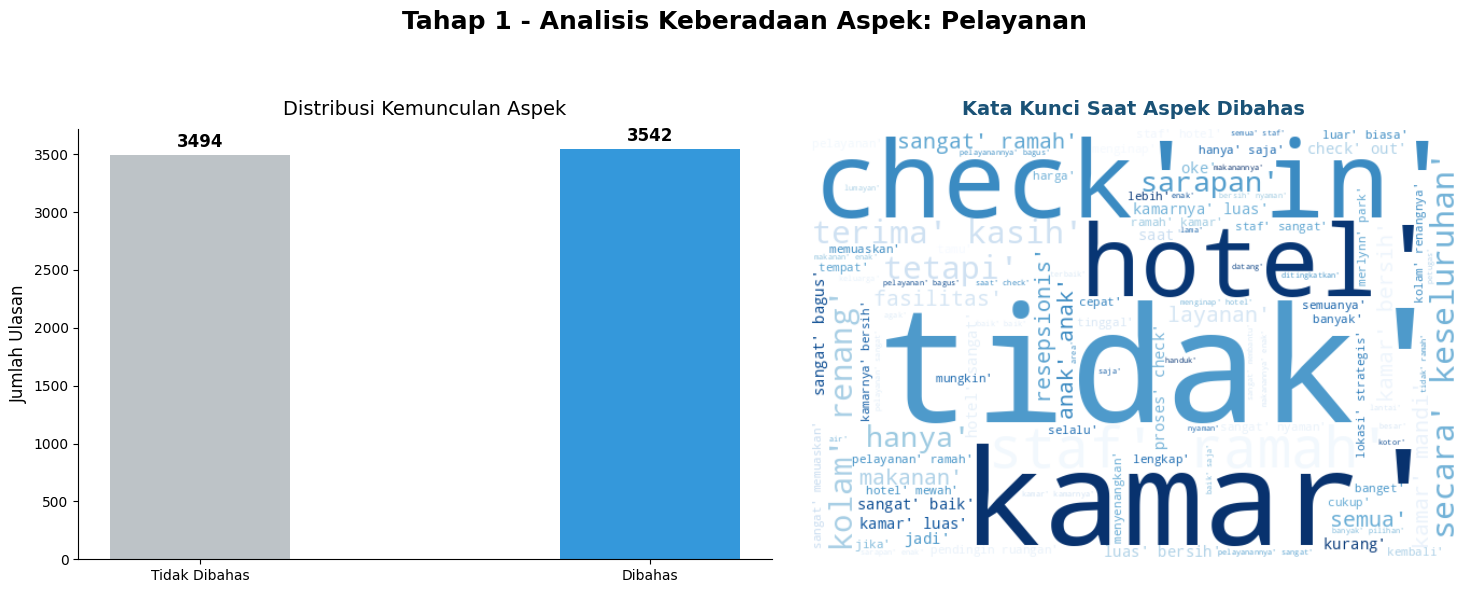

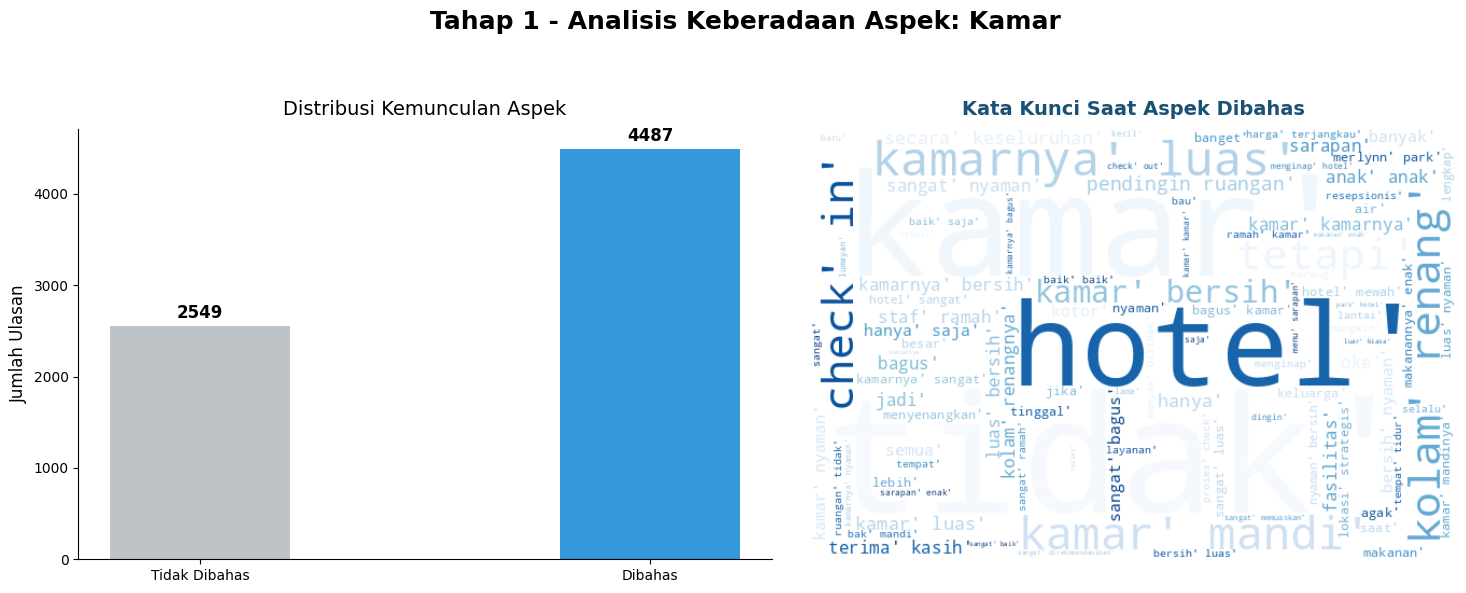

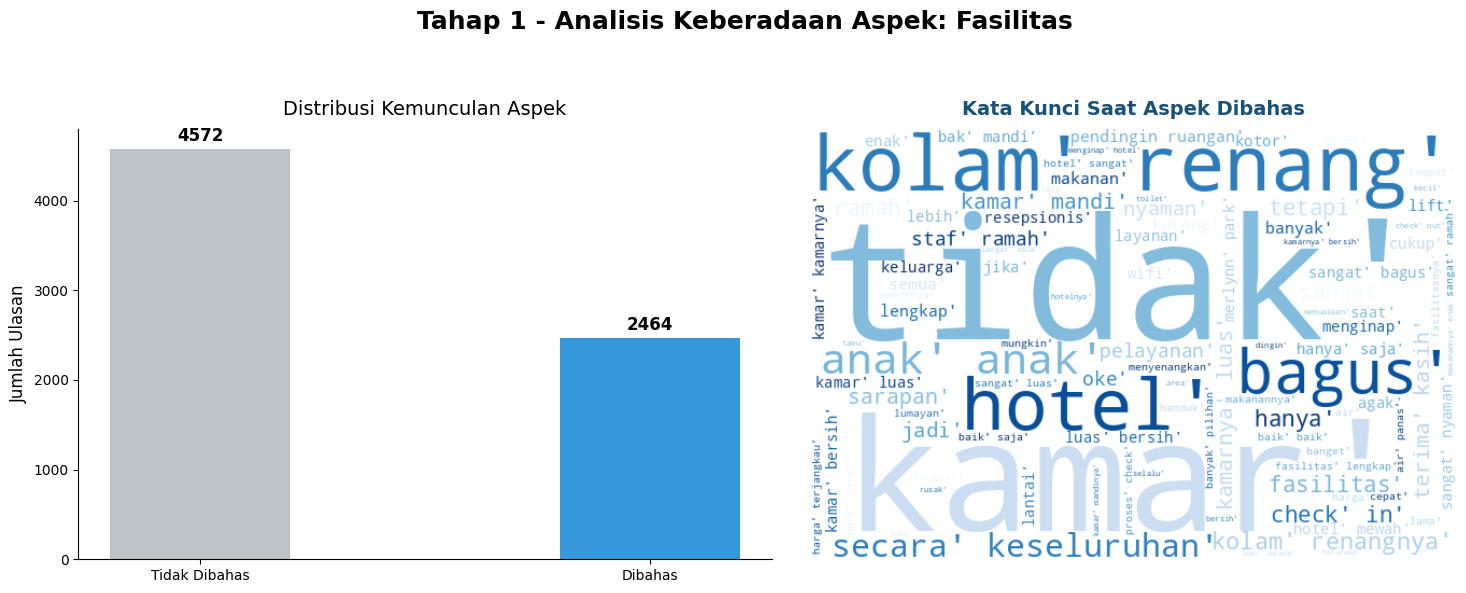

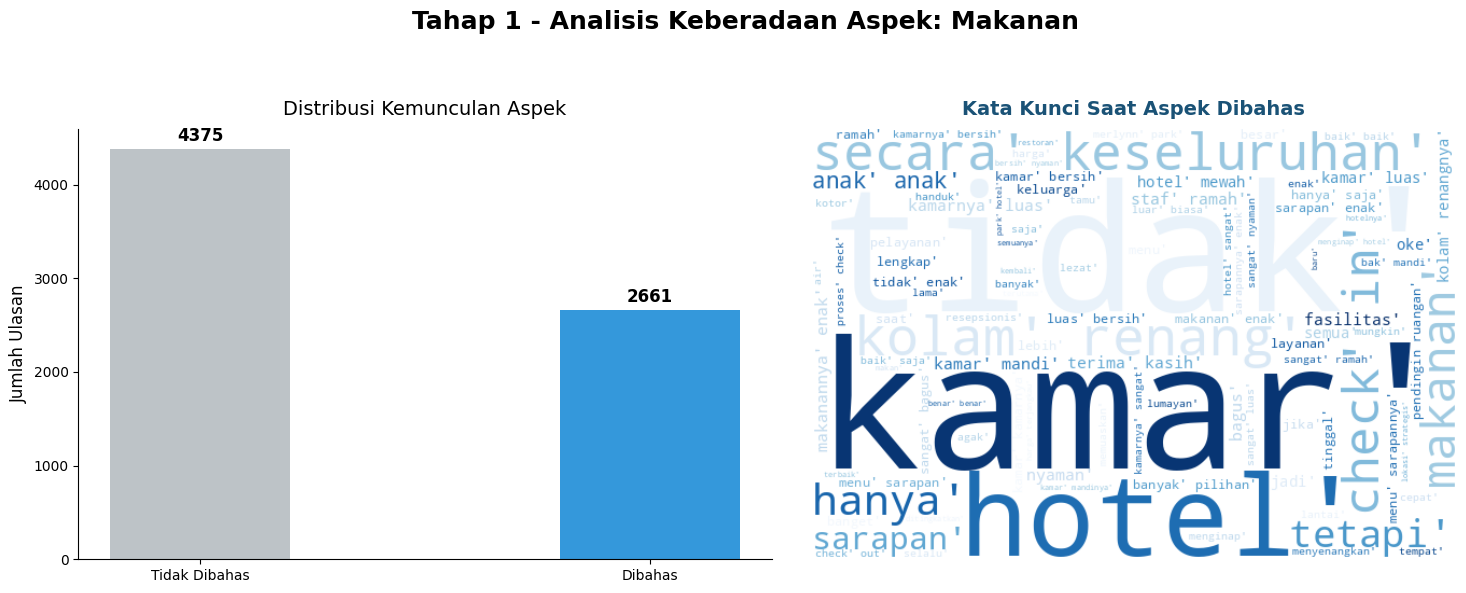

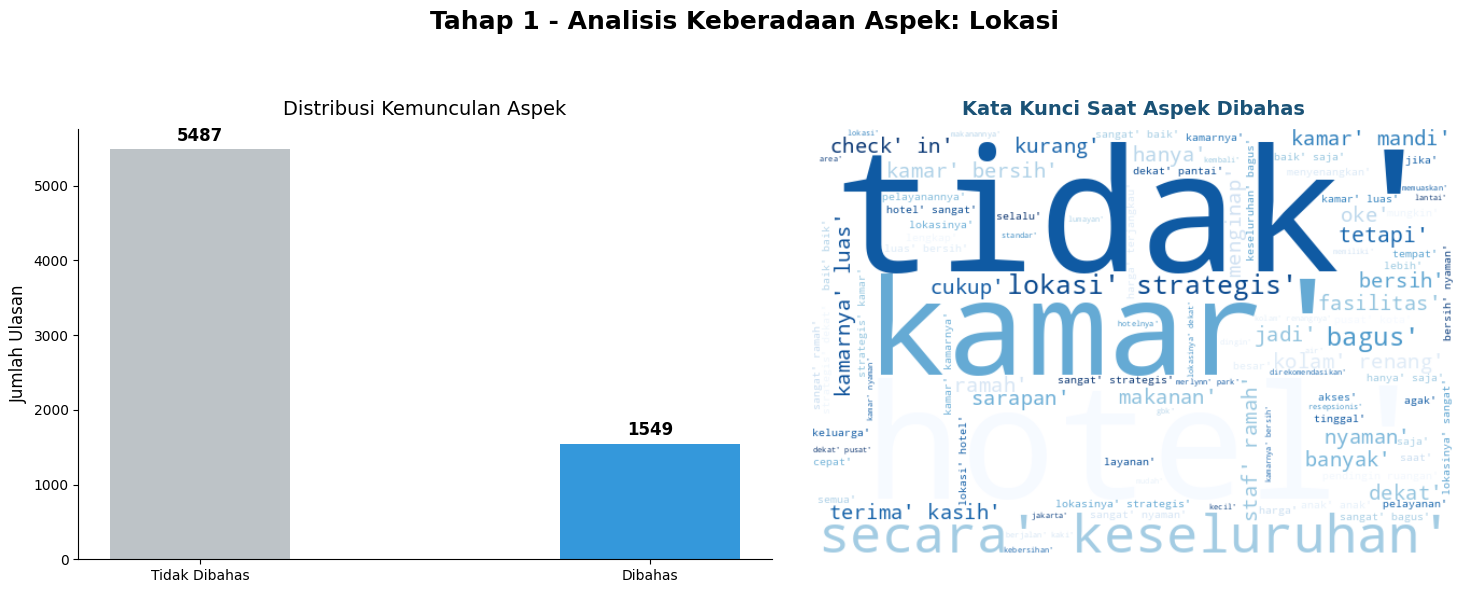

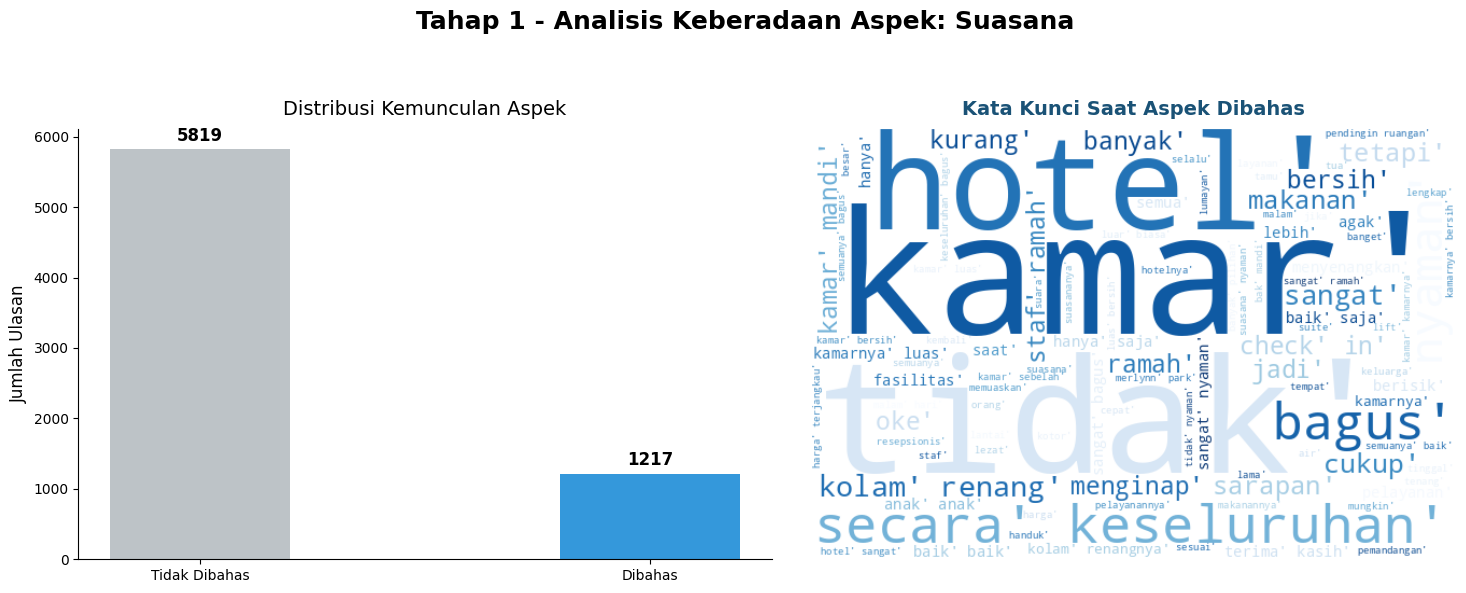

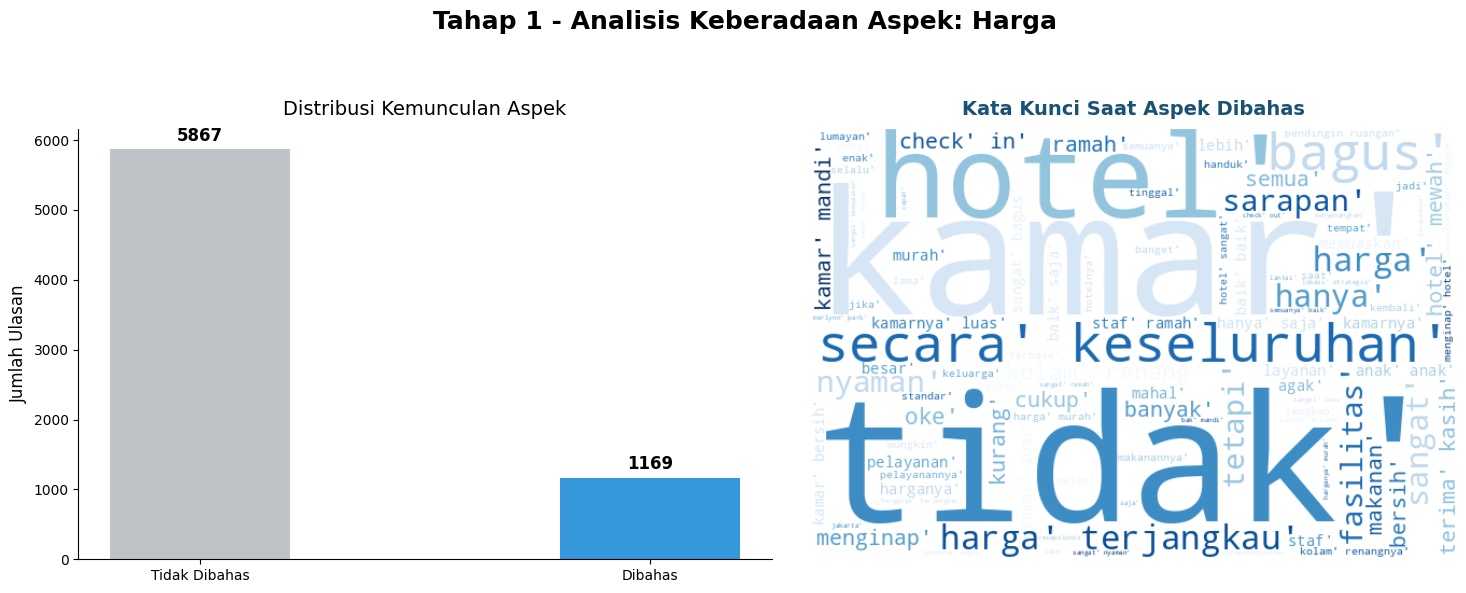

In [ ]:
# ============================================================
# EXPLORASI DATA ANALISIS - TAHAP 1 (DETEKSI ASPEK)
# ============================================================

for aspect in aspects:
    if aspect not in df.columns:
        continue

    df[aspect] = pd.to_numeric(df[aspect], errors='coerce')

    # Hitung Distribusi Tahap 1
    # 0 = Tidak Dibahas, sedangkan 1 dan -1 digabung menjadi Dibahas
    tidak_dibahas = (df[aspect] == 0).sum()
    dibahas = df[aspect].isin([1, -1]).sum()

    # Extract teks ulasan khusus untuk kondisi saat aspek tersebut DIBAHAS
    dibahas_text_aspek = ' '.join(df['final_tokens'][df[aspect].isin([1, -1])].astype(str).tolist())

    # ==========================================
    # MEMBUAT PLOT TAHAP 1 (1 BARIS x 2 KOLOM)
    # ==========================================
    plt.figure(figsize=(15, 6))
    plt.suptitle(f'Tahap 1 - Analisis Keberadaan Aspek: {aspect}', fontsize=18, fontweight='bold', y=0.98)

    # 5.1 Bar Chart Distribusi (Sebelah Kiri)
    ax1 = plt.subplot(1, 2, 1)
    bars = ax1.bar(['Tidak Dibahas', 'Dibahas'], [tidak_dibahas, dibahas], color=['#bdc3c7', '#3498db'], width=0.4)
    ax1.set_title('Distribusi Kemunculan Aspek', fontsize=14, pad=10)
    ax1.set_ylabel('Jumlah Ulasan', fontsize=12)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # Menambahkan angka di atas bar
    for bar in bars:
        height = bar.get_height()
        ax1.annotate(f'{height}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=12)

    # 5.2 WordCloud Saat Aspek Dibahas (Sebelah Kanan)
    ax2 = plt.subplot(1, 2, 2)
    if len(dibahas_text_aspek.strip()) > 0:
        wc_dibahas = WordCloud(
            width=600, height=400,
            background_color='white',
            colormap='Blues',
            max_words=100
        ).generate(dibahas_text_aspek)
        ax2.imshow(wc_dibahas, interpolation='bilinear')
        ax2.set_title('Kata Kunci Saat Aspek Dibahas', fontsize=14, fontweight='bold', color='#1a5276', pad=10)
    else:
        ax2.text(0.5, 0.5, f'Tidak ada data untuk aspek ini', ha='center', va='center', fontsize=12)
    ax2.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

In [ ]:
# Fungsi bantu untuk memastikan token bergabung jadi satu kalimat utuh (string)
def join_tokens(tokens):
    if isinstance(tokens, str):
        try:
            tokens = ast.literal_eval(tokens)
        except (ValueError, SyntaxError):
            pass

    # Jika sudah berupa list, gabungkan dengan spasi
    if isinstance(tokens, list):
        return ' '.join(tokens)

    # Jaga-jaga jika ada tipe data lain atau kosong
    return str(tokens)

# Buat kolom baru bernama 'text_ready' yang berisi kalimat bersih
df['text_ready'] = df['final_tokens'].apply(join_tokens)

In [ ]:
# Siapkan data teks bersih final untuk semua aspek
df_model = df.copy()
df_model['text_ready'] = df_model['text_ready'].astype(str)

for aspect in aspects:
    df_model[aspect] = pd.to_numeric(df_model[aspect], errors='coerce')

print(f"Total data: {len(df_model)}")
for aspect in aspects:
    valid_n = df_model[aspect].isin([-1, 0, 1]).sum()
    print(f"{aspect:<10} -> label valid: {valid_n}")

Total data: 7036
Pelayanan  -> label valid: 7036
Kamar      -> label valid: 7036
Fasilitas  -> label valid: 7036
Makanan    -> label valid: 7036
Lokasi     -> label valid: 7036
Suasana    -> label valid: 7036
Harga      -> label valid: 7036


In [ ]:
# Konfigurasi utama
RANDOM_STATE = 42
TRAIN_RATIO = 0.70
VAL_RATIO_WITHIN_REST = 0.50  # dari 30% sisa -> 15% val, 15% test
panjang_maksimal = 100

print(f"RANDOM_STATE: {RANDOM_STATE}")
print(f"Split final : train={int(TRAIN_RATIO*100)}%, val=15%, test=15%")
print(f"Max length  : {panjang_maksimal}")

RANDOM_STATE: 42
Split final : train=70%, val=15%, test=15%
Max length  : 100


In [ ]:
LEARNING_RATE = 0.001
BATCH_SIZE = 16
EPOCHS = 50
DROPOUT_RATE = 0.3
PATIENCE = 5

MODEL_DIR = 'saved_models'
TOKENIZER_DIR = 'saved_tokenizers'
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(TOKENIZER_DIR, exist_ok=True)

# Load FastText sekali untuk semua aspek
print("Memuat fastText model...")
model_path = '/kaggle/input/datasets/zalfaintannadhifan/cc-id-300/cc.id.300.bin'
ft_model = fasttext.load_model(model_path)
words_set = set(ft_model.get_words())
print("✅ fastText siap")
print(f"Jumlah kata di kamus fastText: {len(words_set):,}")

Memuat fastText model...
✅ fastText siap
Jumlah kata di kamus fastText: 2,000,000


In [ ]:
# Fungsi Split Tahap 1 (Tidak Dibahas [0] vs Dibahas [1])
def split_stage1(df_src, aspek):
    subset = df_src[['text_ready', aspek]].copy()
    subset = subset[subset[aspek].isin([-1, 0, 1])].dropna()
    
    if len(subset) < 60: return None
    
    X = subset['text_ready'].astype(str).values
    # Mapping T1: label 0 tetap 0. Label -1 dan 1 digabung menjadi 1 (artinya dibahas)
    y = subset[aspek].apply(lambda x: 0 if x == 0 else 1).values
    
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_STATE, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=VAL_RATIO_WITHIN_REST, random_state=RANDOM_STATE, stratify=y_temp)
    return X_train, X_val, X_test, y_train, y_val, y_test

In [ ]:
# ============================================================
# PENGECEKAN DISTRIBUSI SPLIT DATA (TRAIN, VAL, TEST)
# ============================================================

print("="*85)
print(" 📊 DISTRIBUSI DATA TAHAP 1: DETEKSI ASPEK")
print("    (0 = Tidak Dibahas, 1 = Dibahas)")
print("="*85)
print(f"{'Aspek':<12} | {'Train Set':<25} | {'Val Set':<10} | {'Test Set':<10} | {'Total'}")
print("-" * 85)

for aspek in aspects:
    splitted = split_stage1(df_model, aspek)
    if splitted is None:
        print(f"{aspek:<12} | ⚠️ Data tidak cukup untuk displit")
        continue

    X_tr, X_va, X_te, y_tr, y_va, y_te = splitted
    
    # Hitung jumlah per kelas di Data Train
    c0_tr = (y_tr == 0).sum()
    c1_tr = (y_tr == 1).sum()
    
    total_aspek = len(y_tr) + len(y_va) + len(y_te)
    
    print(f"{aspek:<12} | {len(y_tr):<5} (0: {c0_tr:<4} | 1: {c1_tr:<4}) | {len(y_va):<10} | {len(y_te):<10} | {total_aspek}")

 📊 DISTRIBUSI DATA TAHAP 1: DETEKSI ASPEK
    (0 = Tidak Dibahas, 1 = Dibahas)
Aspek        | Train Set                 | Val Set    | Test Set   | Total
-------------------------------------------------------------------------------------
Pelayanan    | 4925  (0: 2446 | 1: 2479) | 1055       | 1056       | 7036
Kamar        | 4925  (0: 1784 | 1: 3141) | 1055       | 1056       | 7036
Fasilitas    | 4925  (0: 3200 | 1: 1725) | 1055       | 1056       | 7036
Makanan      | 4925  (0: 3062 | 1: 1863) | 1055       | 1056       | 7036
Lokasi       | 4925  (0: 3841 | 1: 1084) | 1055       | 1056       | 7036
Suasana      | 4925  (0: 4073 | 1: 852 ) | 1055       | 1056       | 7036
Harga        | 4925  (0: 4107 | 1: 818 ) | 1055       | 1056       | 7036


In [ ]:
# BUILD MODEL

# ============================================================
# Attention Layer
# ============================================================
class AttentionLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(AttentionLayer, self).__init__(**kwargs)

    def build(self, input_shape):
        self.W = self.add_weight(
            name='attention_weight',
            shape=(input_shape[-1], 1),
            initializer='glorot_uniform',   
            trainable=True
        )
        self.b = self.add_weight(
            name='attention_bias',
            shape=(1,),                    
            initializer='zeros',
            trainable=True
        )
        super(AttentionLayer, self).build(input_shape)

    def call(self, x):
        # e: (batch, time_steps, 1) — skor relevansi tiap token
        e = tf.keras.activations.tanh(tf.tensordot(x, self.W, axes=1) + self.b)
        
        # a: (batch, time_steps, 1) — bobot attention
        a = tf.keras.activations.softmax(e, axis=1)
        
        # output: (batch, hidden_units) — representasi kontekstual terbobot
        return tf.reduce_sum(x * a, axis=1)

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[-1])
        
def aspect_slug(aspek):
    return aspek.lower().replace(' ', '_')

# ============================================================
# MEMBUAT CUSTOM SPARSE CATEGORICAL FOCAL LOSS UNTUK KERAS 3
# ============================================================
class CustomSparseCategoricalFocalCrossentropy(tf.keras.losses.Loss):
    def __init__(self, gamma=2.0, name='sparse_categorical_focal_crossentropy', **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma

    def call(self, y_true, y_pred):
        # Memastikan tipe data label adalah integer
        y_true = tf.cast(y_true, tf.int32)
        
        # Mengubah label integer menjadi format one-hot di dalam loss
        y_true_one_hot = tf.one_hot(y_true, depth=tf.shape(y_pred)[-1])
        
        # Clip nilai prediksi untuk mencegah nilai log(0) yang bikin crash/NaN
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
        
        # Rumus dasar Cross Entropy
        cross_entropy = -y_true_one_hot * tf.math.log(y_pred)
        
        # Rumus Focal Loss: (1 - p)^gamma * Cross Entropy
        focal_loss = tf.math.pow(1.0 - y_pred, self.gamma) * cross_entropy
        
        return tf.reduce_sum(focal_loss, axis=-1)

# ============================================================
# BUILD MODEL
# ============================================================

def build_model(vocab_size, embedding_matrix, dropout_rate=DROPOUT_RATE):
    input_layer = tf.keras.layers.Input(shape=(panjang_maksimal,), name='Input_Teks')

    # FastText Embedding
    embedding_layer = tf.keras.layers.Embedding(
        input_dim=vocab_size,
        output_dim=300,
        weights=[embedding_matrix],
        trainable=False, 
        name='FastText_Embedding'
    )(input_layer)

    # REM 1: Spatial Dropout (Membuang 20% fitur kata agar tidak menghafal)
    x = tf.keras.layers.SpatialDropout1D(0.2, name='Spatial_Dropout')(embedding_layer)

    # TAMBAHAN BARU: Layer Conv1D untuk menangkap konteks N-Gram (misal: "tidak bagus")
    x = tf.keras.layers.Conv1D(
        filters=64, 
        kernel_size=2, 
        padding='same', 
        activation='relu',
        name='Conv1D_Bigram'
    )(x)

    # BiLSTM: memproses urutan kata dari dua arah
    # REM 2: BiLSTM dengan Dropout di dalam
    x = tf.keras.layers.Bidirectional(
        tf.keras.layers.LSTM(128, return_sequences=True, dropout=dropout_rate), name='BiLSTM')(x)

    # Attention: memberi bobot ke token yang paling relevan
    x = AttentionLayer(name='Attention')(x)
    x = tf.keras.layers.Dropout(dropout_rate, name='Dropout')(x)
    
    # Output: 2 kelas (Dibahas & Tidak Dibahas, Positif & Negatif)
    output = tf.keras.layers.Dense(
        2,
        activation='softmax',
        kernel_regularizer=l2(1e-4),
        name='Output_Softmax'
    )(x)

    model = tf.keras.Model(inputs=input_layer, outputs=output, name='BiLSTM_Attention_TwoStage')
    model.compile(
        loss=CustomSparseCategoricalFocalCrossentropy(gamma=2.0),
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        metrics=['accuracy']
    )
    return model

In [ ]:
all_results_t1 = {}
all_histories_t1 = {}
all_predictions_t1 = {}
all_tokenizers_t1 = {}

for aspek in aspects:
    print("\n" + "=" * 60)
    print(f"🚀 TRAINING TAHAP 1 (DETEKSI): {aspek.upper()}")
    print("=" * 60)

    splitted = split_stage1(df_model, aspek)
    if splitted is None: 
        print(f"⚠️ Aspek {aspek} dilewati karena data tidak mencukupi.")
        continue

    X_tr_text, X_va_text, X_te_text, y_tr, y_va, y_te = splitted

    # Menghitung Class Weight untuk menyeimbangkan kelas pelatihan secara otomatis
    weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
    class_weight_dict = dict(enumerate(weights))
    print(f"Bobot penalti kelas Tahap 1 diterapkan: {class_weight_dict}")

    # Fitting Tokenizer
    tokenizer = Tokenizer(oov_token='<OOV>')
    tokenizer.fit_on_texts(X_tr_text)
    all_tokenizers_t1[aspek] = tokenizer

    X_tr = pad_sequences(tokenizer.texts_to_sequences(X_tr_text), maxlen=panjang_maksimal, padding='post', truncating='post')
    X_va = pad_sequences(tokenizer.texts_to_sequences(X_va_text), maxlen=panjang_maksimal, padding='post', truncating='post')
    X_te = pad_sequences(tokenizer.texts_to_sequences(X_te_text), maxlen=panjang_maksimal, padding='post', truncating='post')

    # FastText Embedding Matrix
    vocab_size = len(tokenizer.word_index) + 1
    embedding_matrix = np.zeros((vocab_size, 300))
    for word, i in tokenizer.word_index.items():
        embedding_matrix[i] = ft_model.get_word_vector(word)

    model = build_model(vocab_size=vocab_size, embedding_matrix=embedding_matrix)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
    ]

    # Proses latih menggunakan class_weight
    history = model.fit(
        X_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_data=(X_va, y_va),
        class_weight=class_weight_dict, callbacks=callbacks, verbose=1
    )
    
    y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)

    # Simpan riwayat seperti kodemu
    all_histories_t1[aspek] = history.history
    all_predictions_t1[aspek] = (y_te, y_pred)
    all_results_t1[aspek] = classification_report(y_te, y_pred, target_names=['Tidak Dibahas', 'Dibahas'], output_dict=True, zero_division=0)
    
    # Menyimpan Model & Tokenizer Tahap 1
    slug = aspect_slug(aspek)
    model.save(f'{MODEL_DIR}/t1_deteksi_{slug}.keras')
    with open(f'{TOKENIZER_DIR}/tokenizer_t1_{slug}.json', 'w', encoding='utf-8') as f:
        f.write(tokenizer.to_json())
        
    print(f"✅ [Tahap 1 - {aspek}] Selesai T1! Macro F1-Score test: {all_results_t1[aspek]['macro avg']['f1-score'] * 100:.2f}%")

print("\n" + "="*60)
print("  ARSITEKTUR MODEL BiLSTM + ATTENTION")
print("="*60)
model_preview = build_model(vocab_size, embedding_matrix)
model_preview.summary()
print("="*60 + "\n")


🚀 TRAINING TAHAP 1 (DETEKSI): PELAYANAN
Bobot penalti kelas Tahap 1 diterapkan: {0: np.float64(1.0067457072771873), 1: np.float64(0.9933440903590157)}


I0000 00:00:1781188368.242215     183 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1781188368.248322     183 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Epoch 1/50


I0000 00:00:1781188374.803094     261 cuda_dnn.cc:529] Loaded cuDNN version 91002


308/308 ━━━━━━━━━━━━━━━━━━━━ 13s 19ms/step - accuracy: 0.7129 - loss: 0.1386 - val_accuracy: 0.8882 - val_loss: 0.0808 - learning_rate: 0.0010
Epoch 2/50
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9066 - loss: 0.0656 - val_accuracy: 0.9156 - val_loss: 0.0649 - learning_rate: 0.0010
Epoch 3/50
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9311 - loss: 0.0531 - val_accuracy: 0.9251 - val_loss: 0.0632 - learning_rate: 0.0010
Epoch 4/50
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9399 - loss: 0.0476 - val_accuracy: 0.9403 - val_loss: 0.0436 - learning_rate: 0.0010
Epoch 5/50
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9472 - loss: 0.0398 - val_accuracy: 0.9498 - val_loss: 0.0437 - learning_rate: 0.0010
Epoch 6/50
305/308 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9506 - loss: 0.0368
Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
308/308 ━━━━━━━━━━━━━━━━━━━━ 5s 15ms/step - accuracy: 0.9505 - loss: 0.0368 - val_

Model: "BiLSTM_Attention_TwoStage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Teks (InputLayer)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FastText_Embedding (Embedding)  │ (None, 100, 300)       │     1,368,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Spatial_Dropout                 │ (None, 100, 300)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_Bigram (Conv1D)          │ (None, 100, 64)        │        38,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiLSTM (Bidirectional)          │ (None, 100, 256)       │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Attention (AttentionLayer)      │ (None, 256)            │           257 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Softmax (Dense)          │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,604,867 (6.12 MB)

 Trainable params: 236,867 (925.26 KB)

 Non-trainable params: 1,368,000 (5.22 MB)

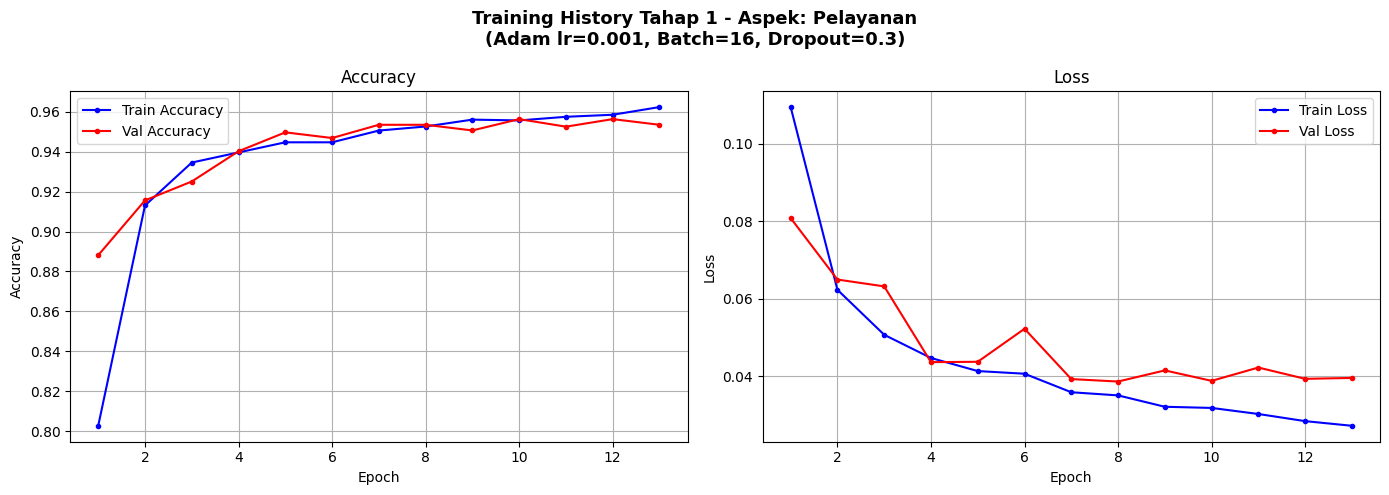

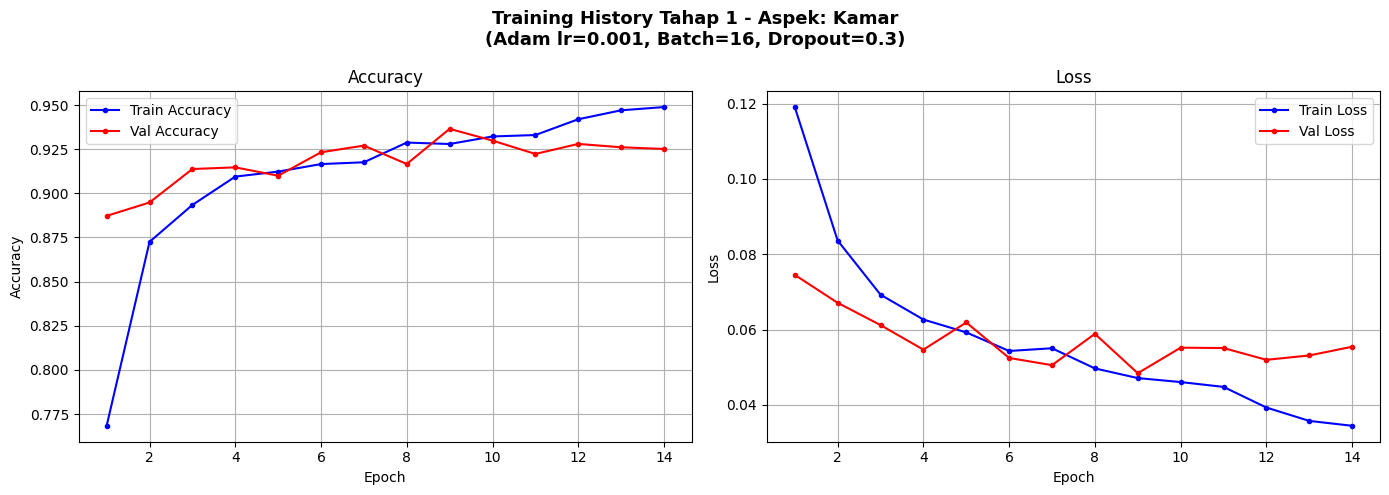

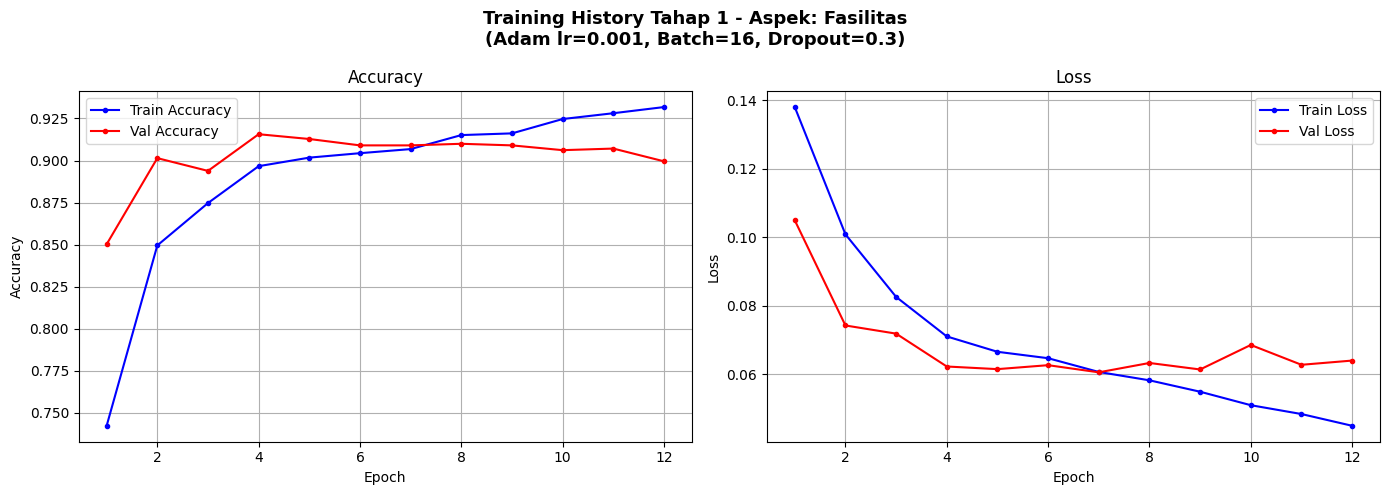

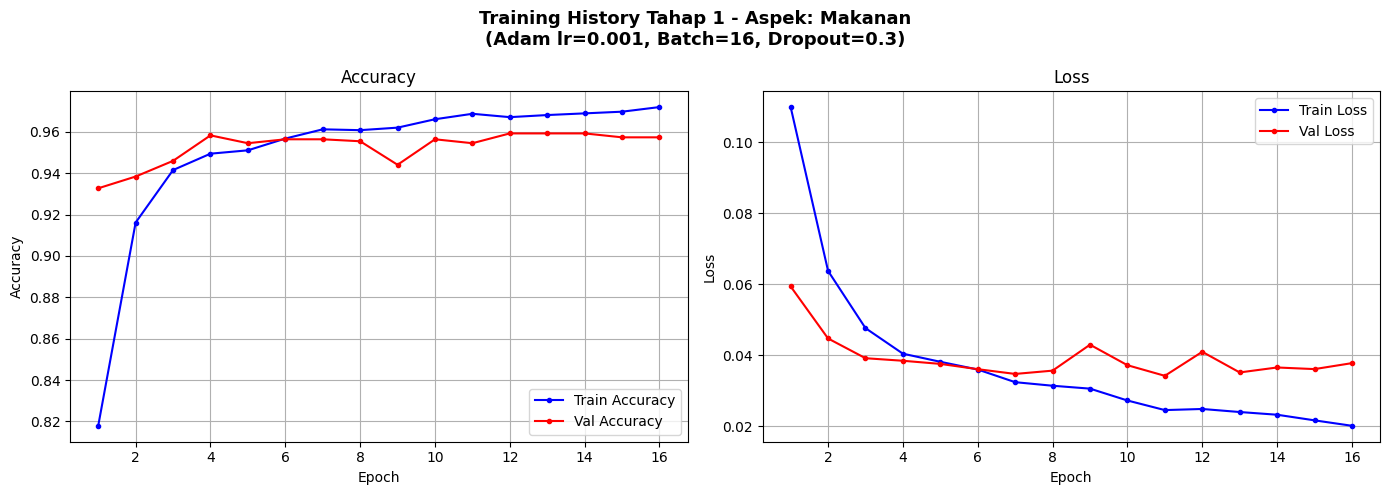

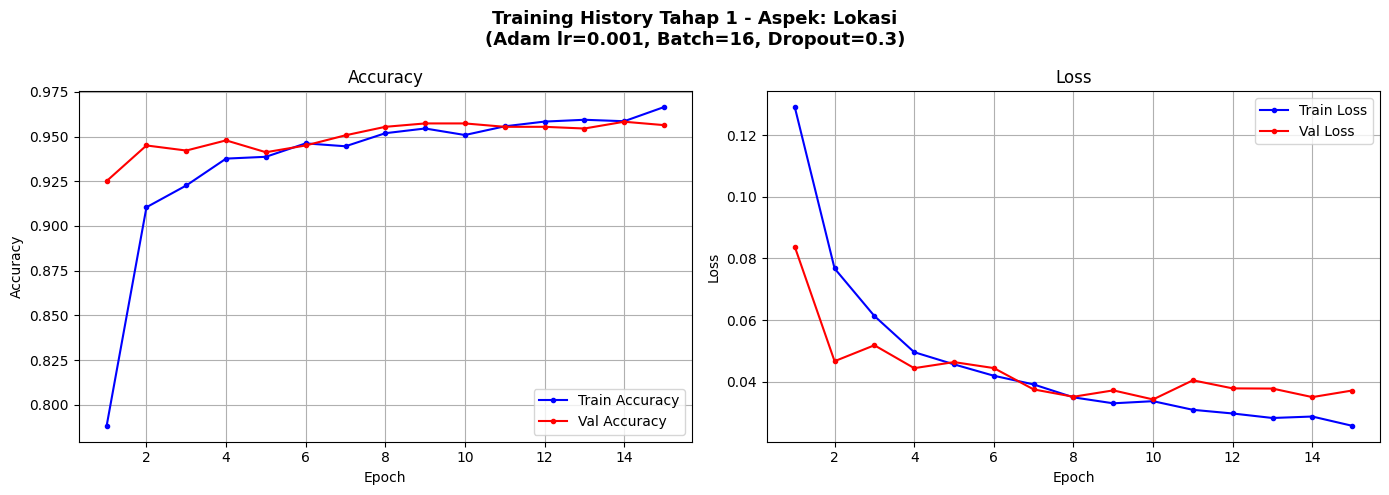

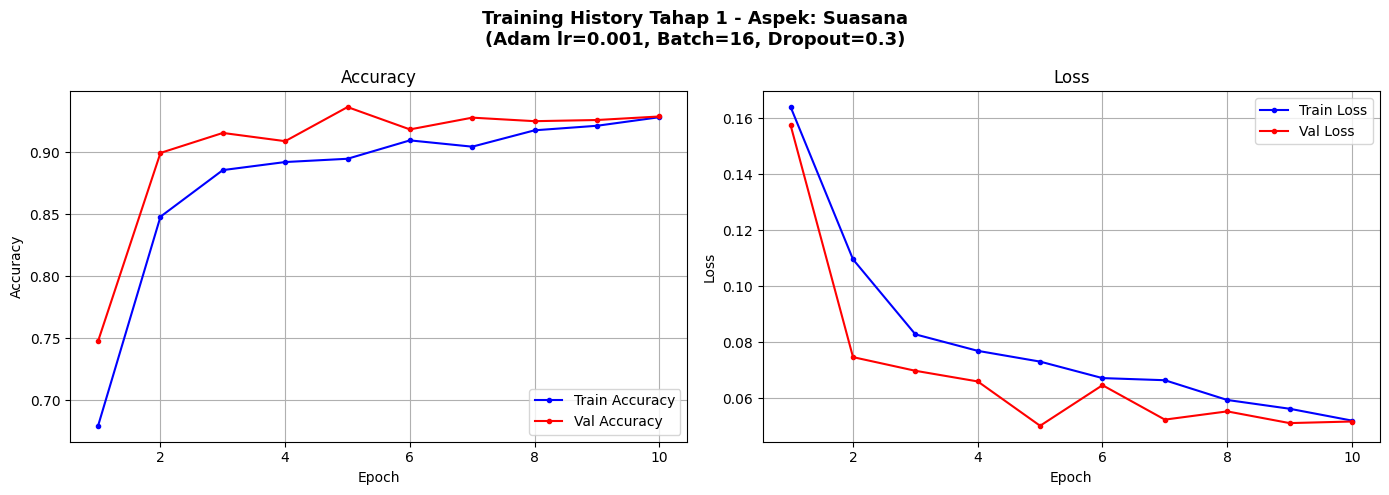

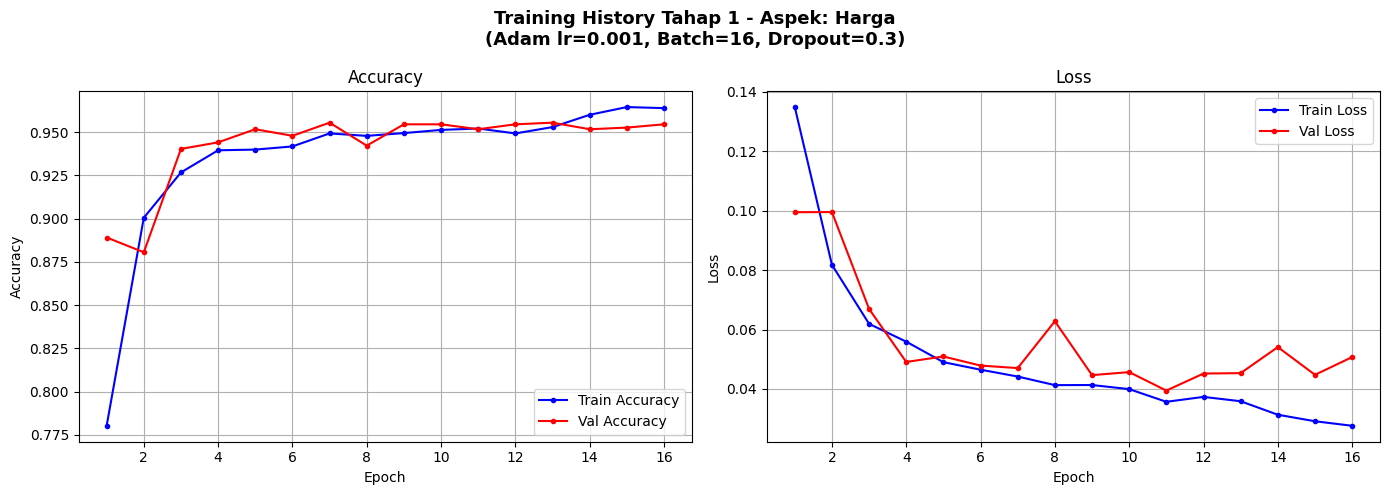

In [ ]:
def plot_history(history_dict, aspek_name, tahap_name):
    acc = history_dict['accuracy']; val_acc = history_dict['val_accuracy']
    loss = history_dict['loss']; val_loss = history_dict['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))
    plt.suptitle(f'Training History {tahap_name} - Aspek: {aspek_name}\n(Adam lr={LEARNING_RATE}, Batch={BATCH_SIZE}, Dropout={DROPOUT_RATE})', fontsize=13, fontweight='bold')
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-o', markersize=3, label='Train Accuracy')
    plt.plot(epochs, val_acc, 'r-o', markersize=3, label='Val Accuracy')
    plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-o', markersize=3, label='Train Loss')
    plt.plot(epochs, val_loss, 'r-o', markersize=3, label='Val Loss')
    plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()

for aspek in aspects:
    if aspek in all_histories_t1: plot_history(all_histories_t1[aspek], aspek, "Tahap 1")

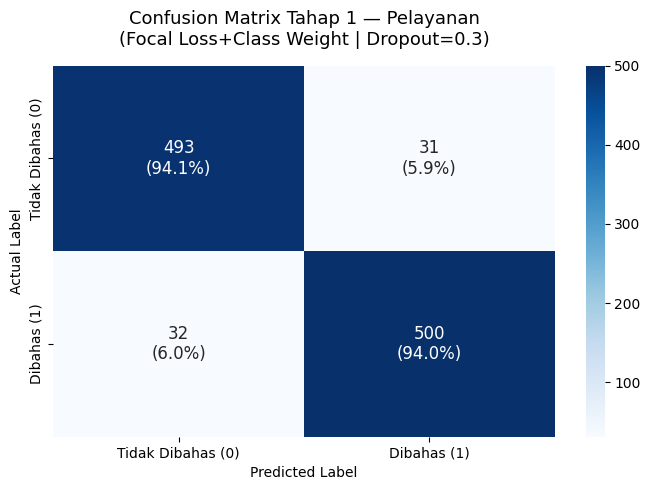

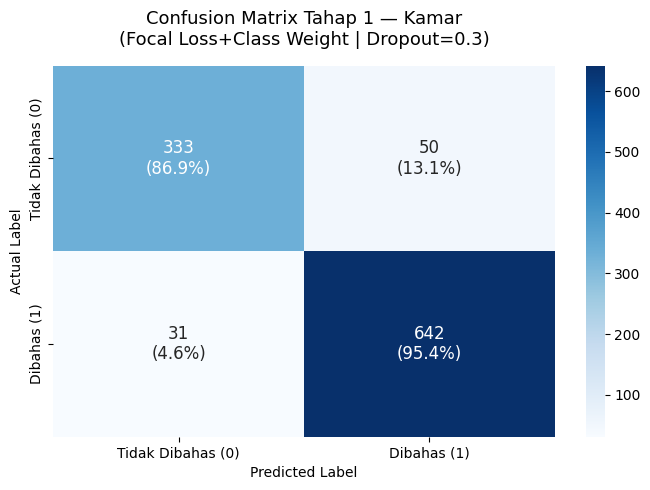

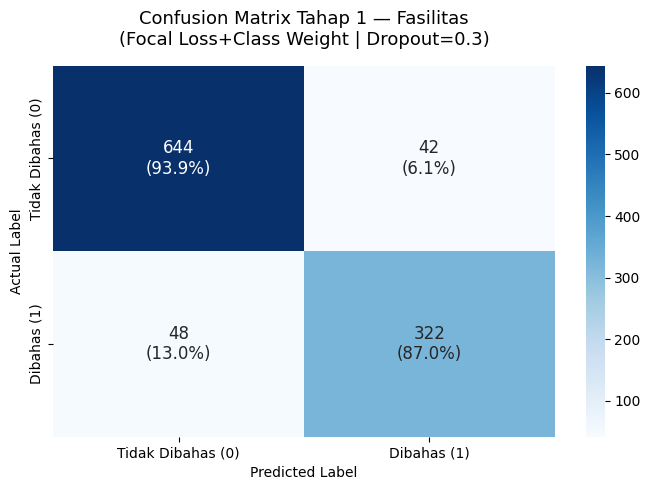

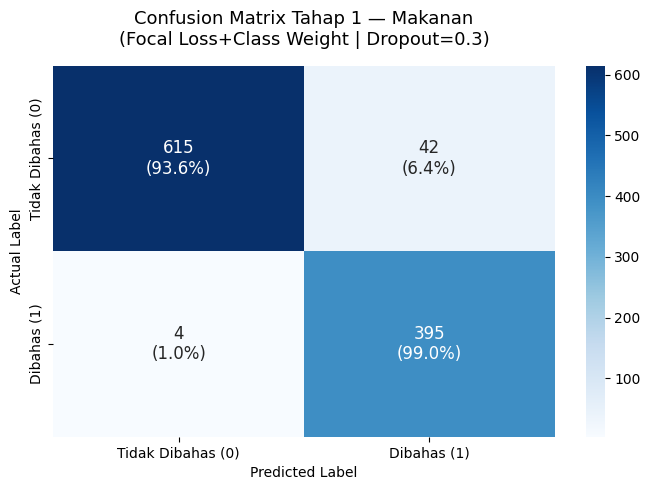

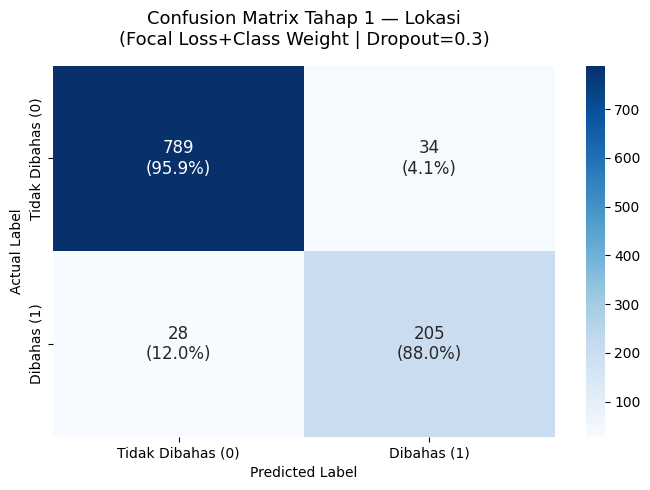

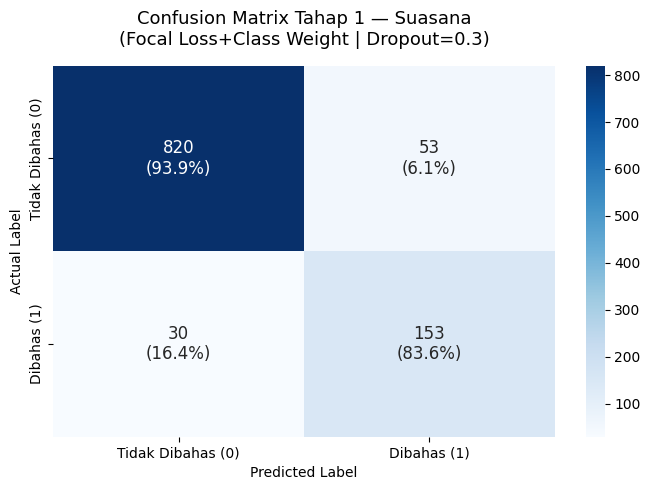

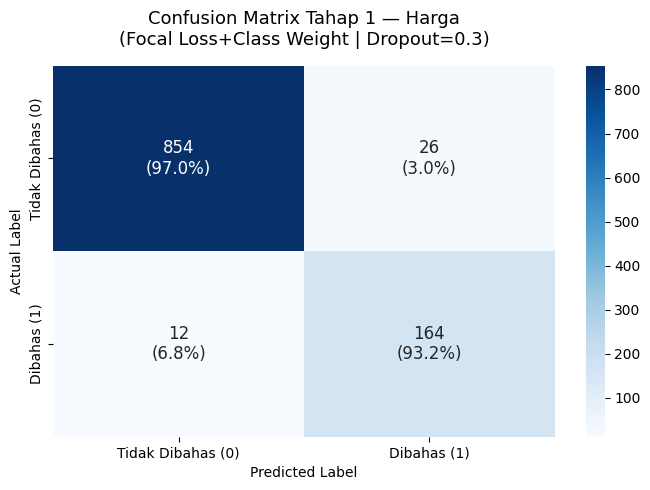

In [ ]:
def plot_confusion_matrix(y_true, y_pred, aspek_name, tahap_name, labels):
    cm = confusion_matrix(y_true, y_pred)
    with np.errstate(divide='ignore', invalid='ignore'):
        cm_percent = np.nan_to_num(cm.astype('float') / cm.sum(axis=1)[:, np.newaxis])
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]): annot[i, j] = f'{cm[i,j]}\n({cm_percent[i,j]*100:.1f}%)'

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', xticklabels=labels, yticklabels=labels, annot_kws={"size": 12})
    plt.title(f'Confusion Matrix {tahap_name} — {aspek_name}\n(Focal Loss+Class Weight | Dropout={DROPOUT_RATE})', pad=15, fontsize=13)
    plt.ylabel('Actual Label'); plt.xlabel('Predicted Label'); plt.tight_layout(); plt.show()

for aspek in aspects:
    if aspek in all_predictions_t1:
        y_true, y_pred = all_predictions_t1[aspek]
        plot_confusion_matrix(y_true, y_pred, aspek, "Tahap 1", ['Tidak Dibahas (0)', 'Dibahas (1)'])

In [ ]:
rows_t1 = []
for aspek in aspects:
    if aspek not in all_predictions_t1 or aspek not in all_results_t1: continue
    y_true, y_pred = all_predictions_t1[aspek]; r = all_results_t1[aspek]
    rows_t1.append({
        'Aspek': aspek,
        'Accuracy (%)': round(accuracy_score(y_true, y_pred) * 100, 2),
        'Macro Precision': round(r['macro avg']['precision'] * 100, 2),
        'Macro Recall': round(r['macro avg']['recall'] * 100, 2),
        'Macro F1 (%)': round(r['macro avg']['f1-score'] * 100, 2),
        'Weighted F1 (%)': round(r['weighted avg']['f1-score'] * 100, 2),
    })
df_summary_t1 = pd.DataFrame(rows_t1).set_index('Aspek') if rows_t1 else pd.DataFrame()

print("\n" + "=" * 70)
print("HASIL MODEL TWO-STAGE (FOCAL LOSS + CLASS WEIGHT)")
print(
    f"Hyperparameter: Adam lr={LEARNING_RATE} | "
    f"Batch={BATCH_SIZE} | Dropout={DROPOUT_RATE} | "
    f"Early Stop patience={PATIENCE}"
)
print("=" * 70)

if len(df_summary_t1) == 0:
    print("Belum ada aspek yang berhasil ditraining.")
else:
    print(df_summary_t1.to_string())
    print("-" * 70)
    print(f"Rata-rata Macro F1  : {df_summary_t1['Macro F1 (%)'].mean():.2f}%")
    print(f"Rata-rata Accuracy  : {df_summary_t1['Accuracy (%)'].mean():.2f}%")
print("=" * 70)


HASIL MODEL TWO-STAGE (FOCAL LOSS + CLASS WEIGHT)
Hyperparameter: Adam lr=0.001 | Batch=16 | Dropout=0.3 | Early Stop patience=5
           Accuracy (%)  Macro Precision  Macro Recall  Macro F1 (%)  Weighted F1 (%)
Aspek                                                                                
Pelayanan         94.03            94.03         94.03         94.03            94.03
Kamar             92.33            92.13         91.17         91.61            92.29
Fasilitas         91.48            90.76         90.45         90.60            91.46
Makanan           95.64            94.87         96.30         95.45            95.68
Lokasi            94.13            91.17         91.93         91.54            94.16
Suasana           92.14            85.37         88.77         86.92            92.32
Harga             96.40            92.47         95.11         93.72            96.46
----------------------------------------------------------------------
Rata-rata Macro F1  : 91.

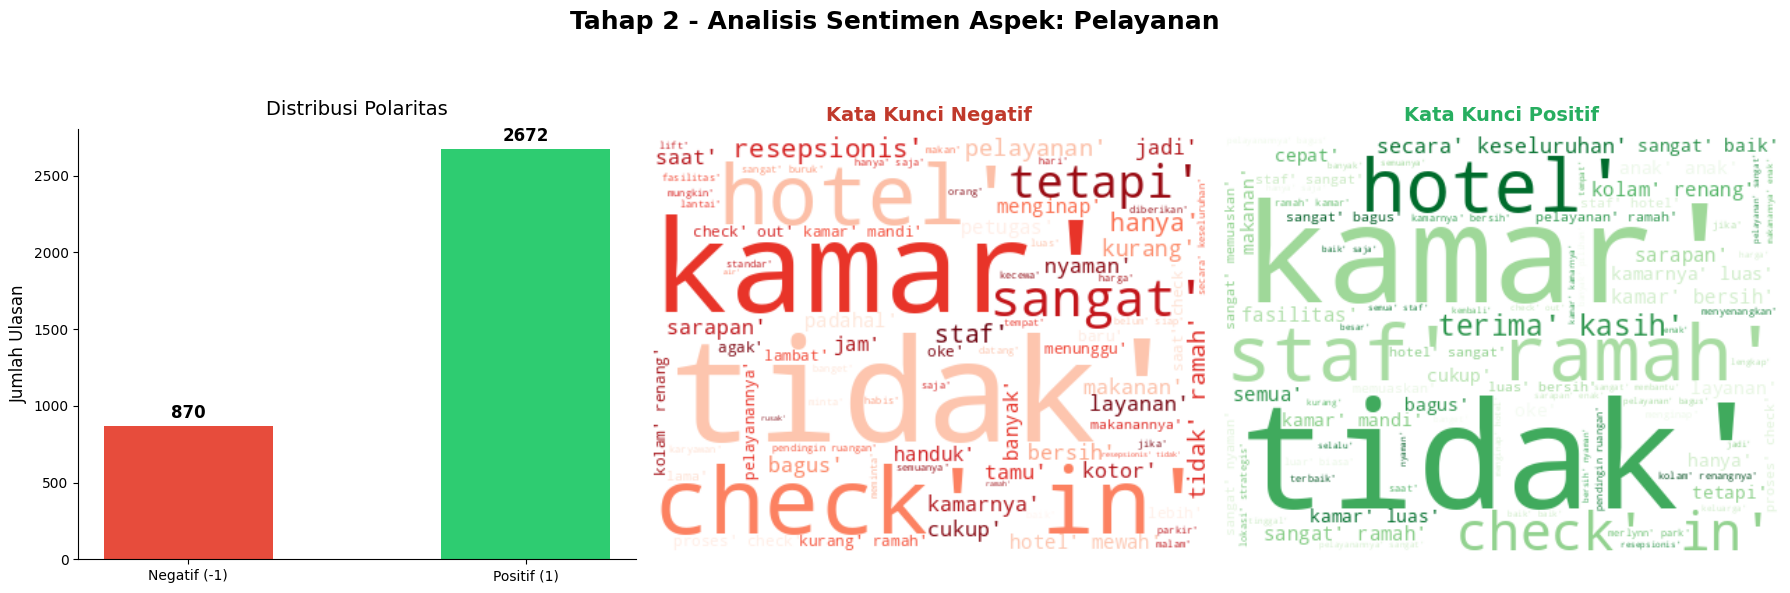

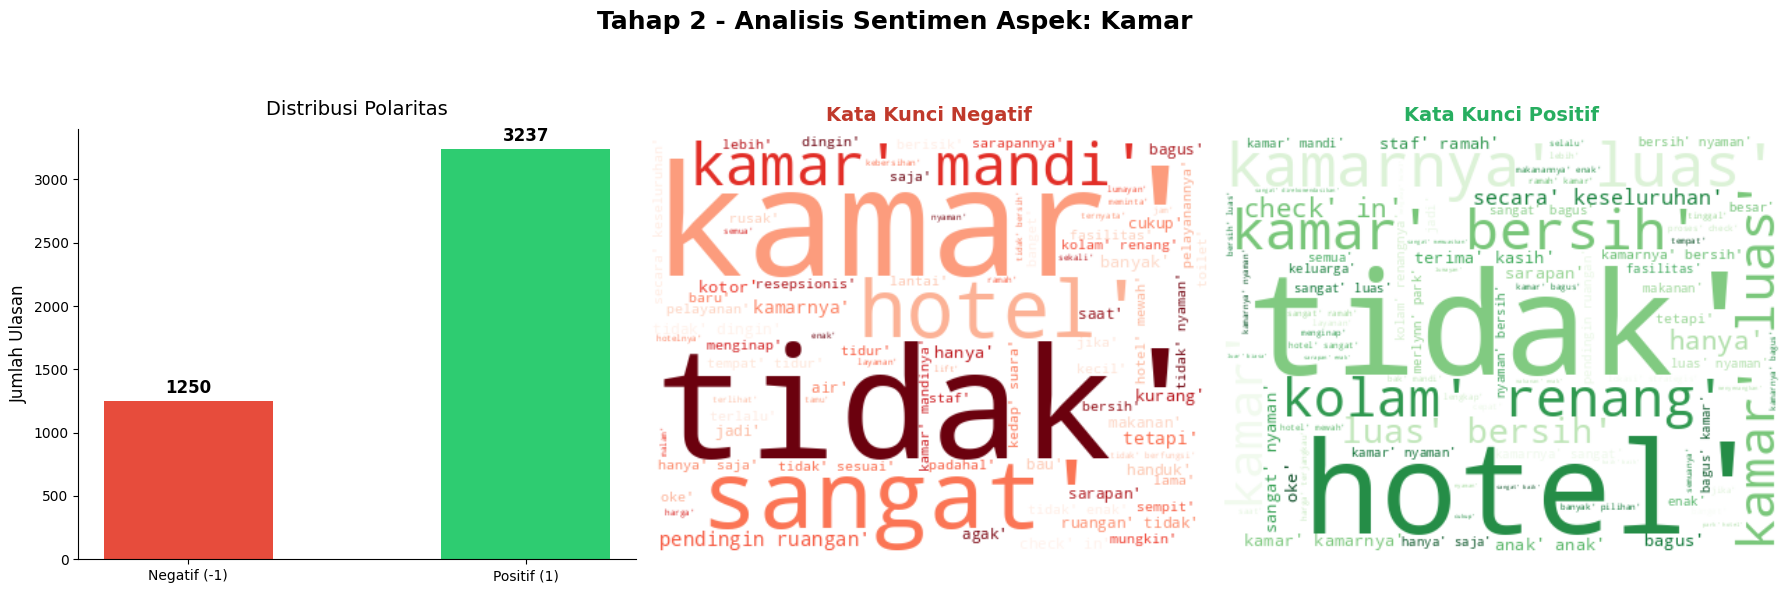

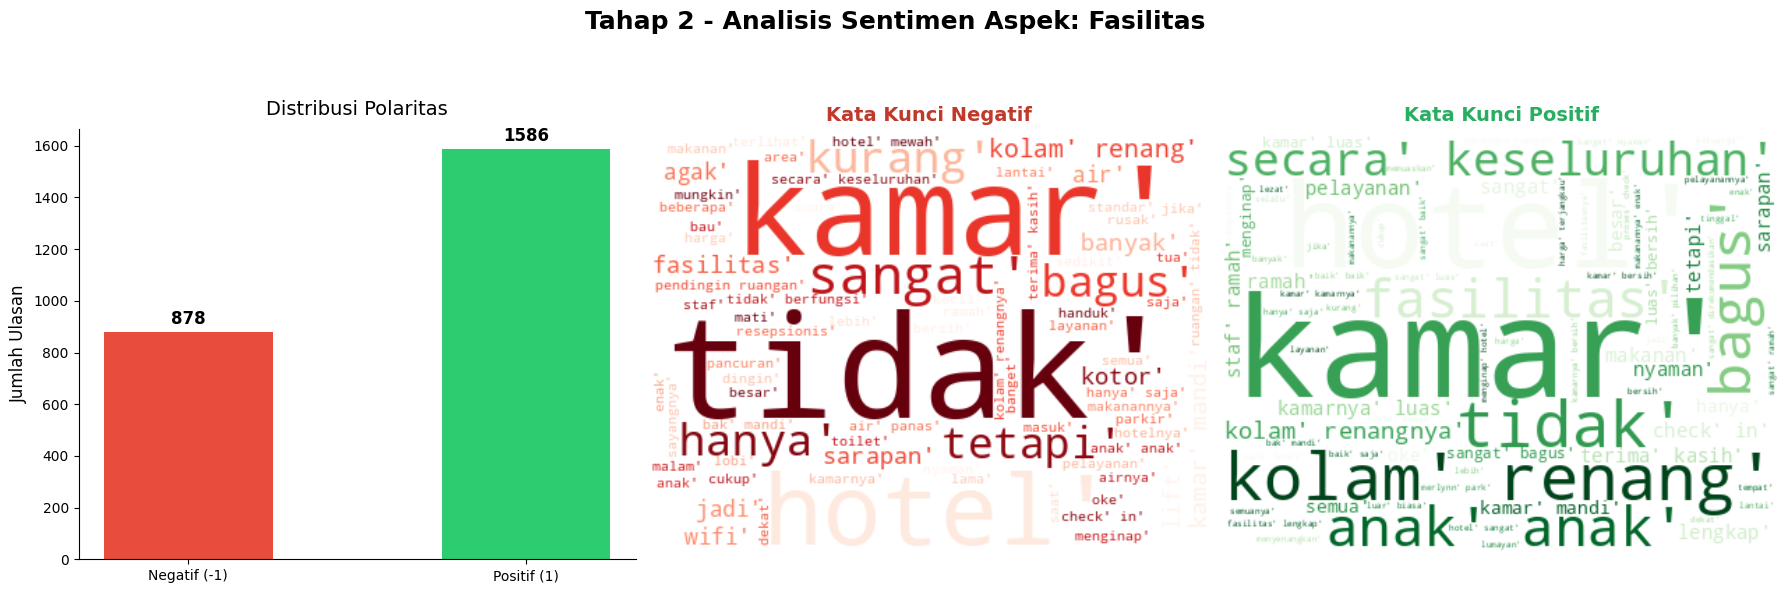

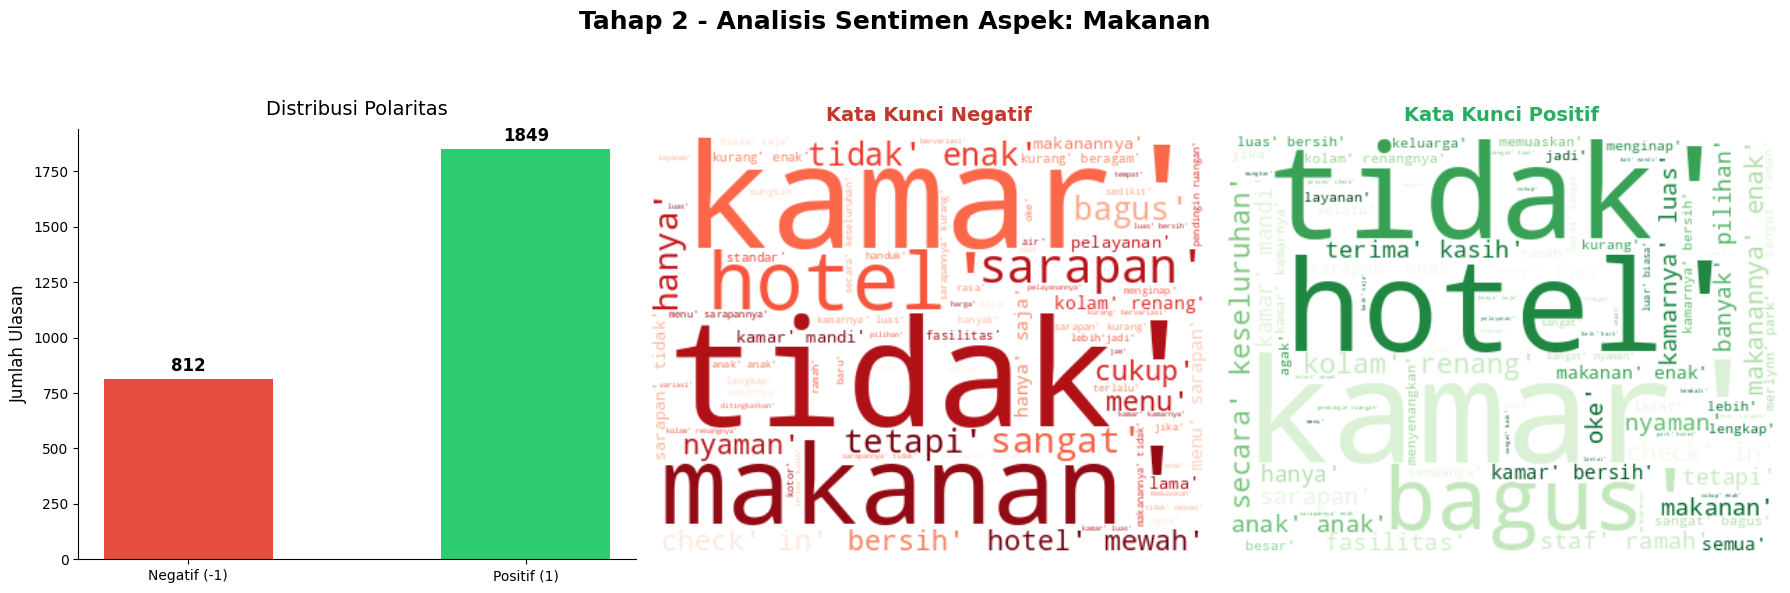

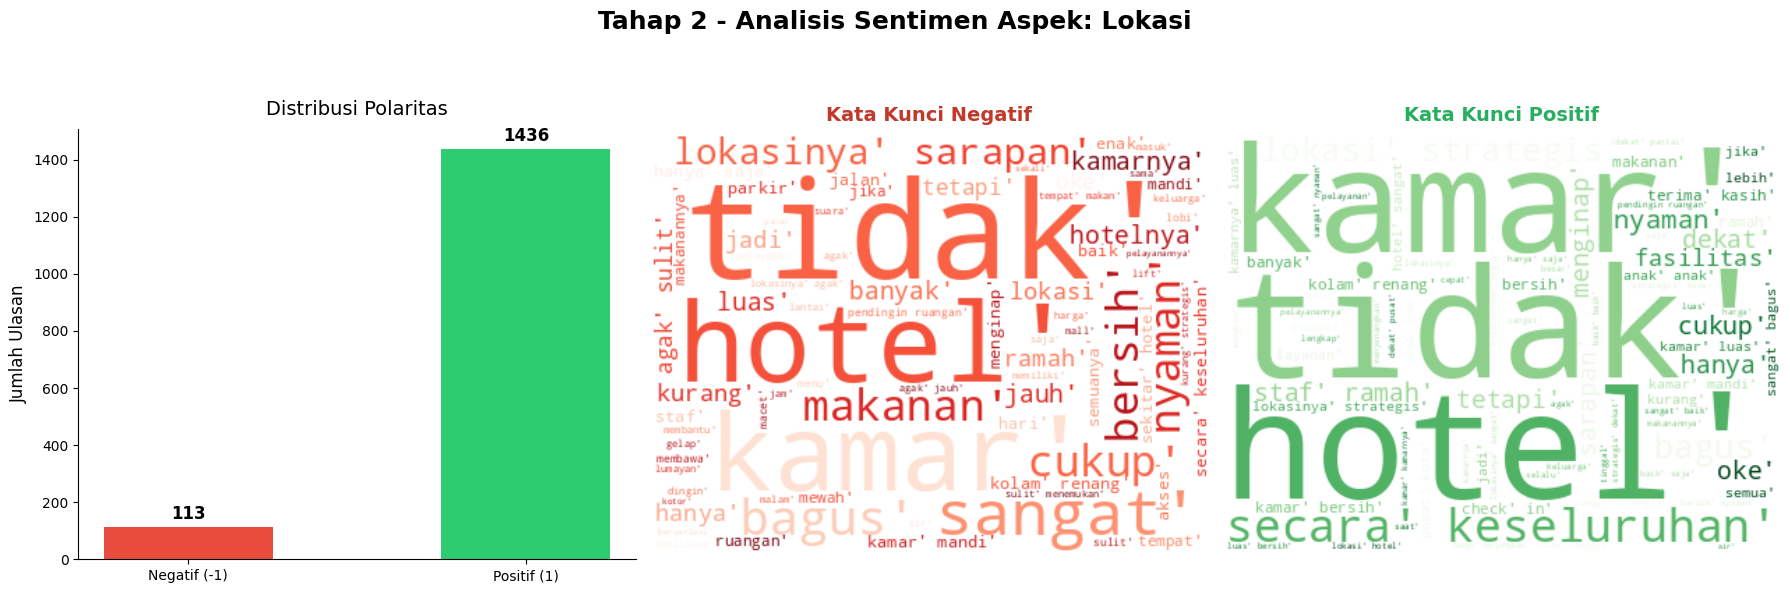

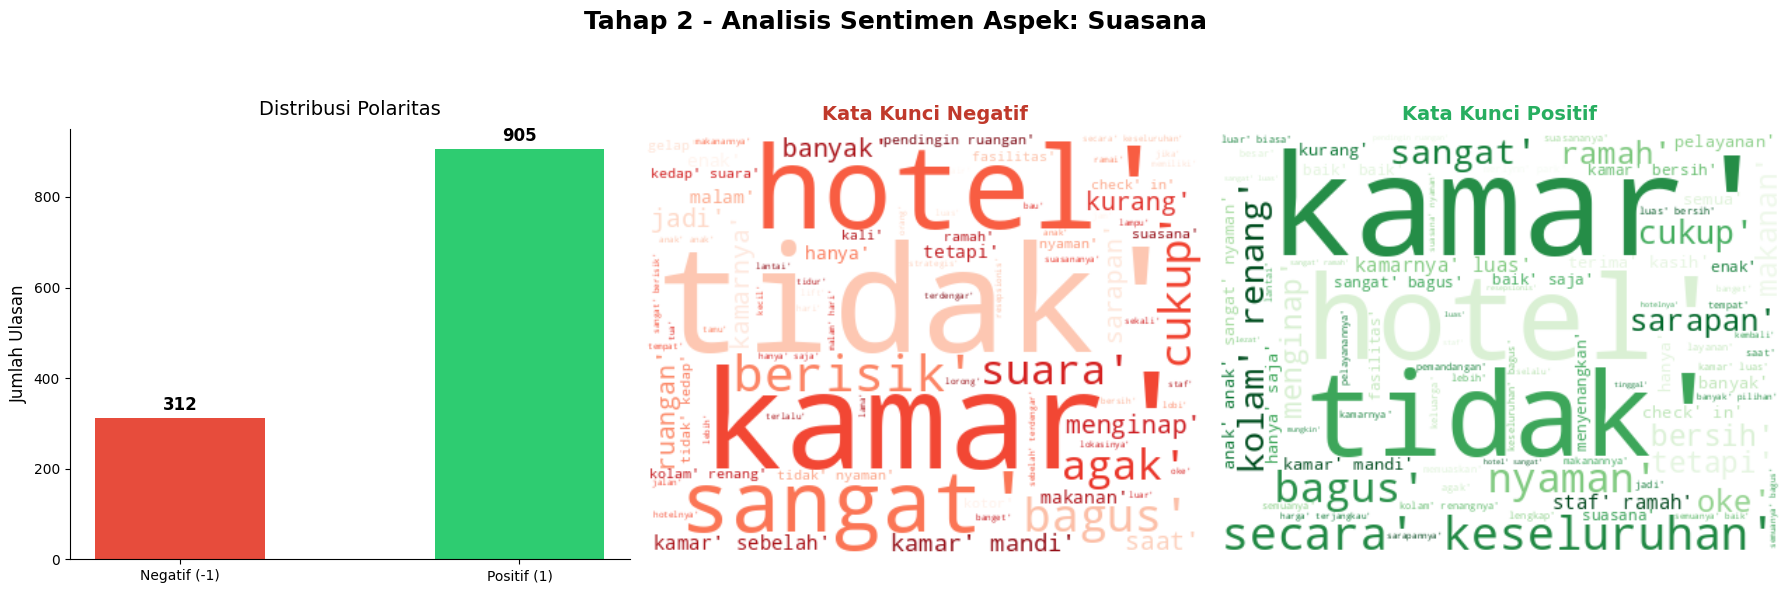

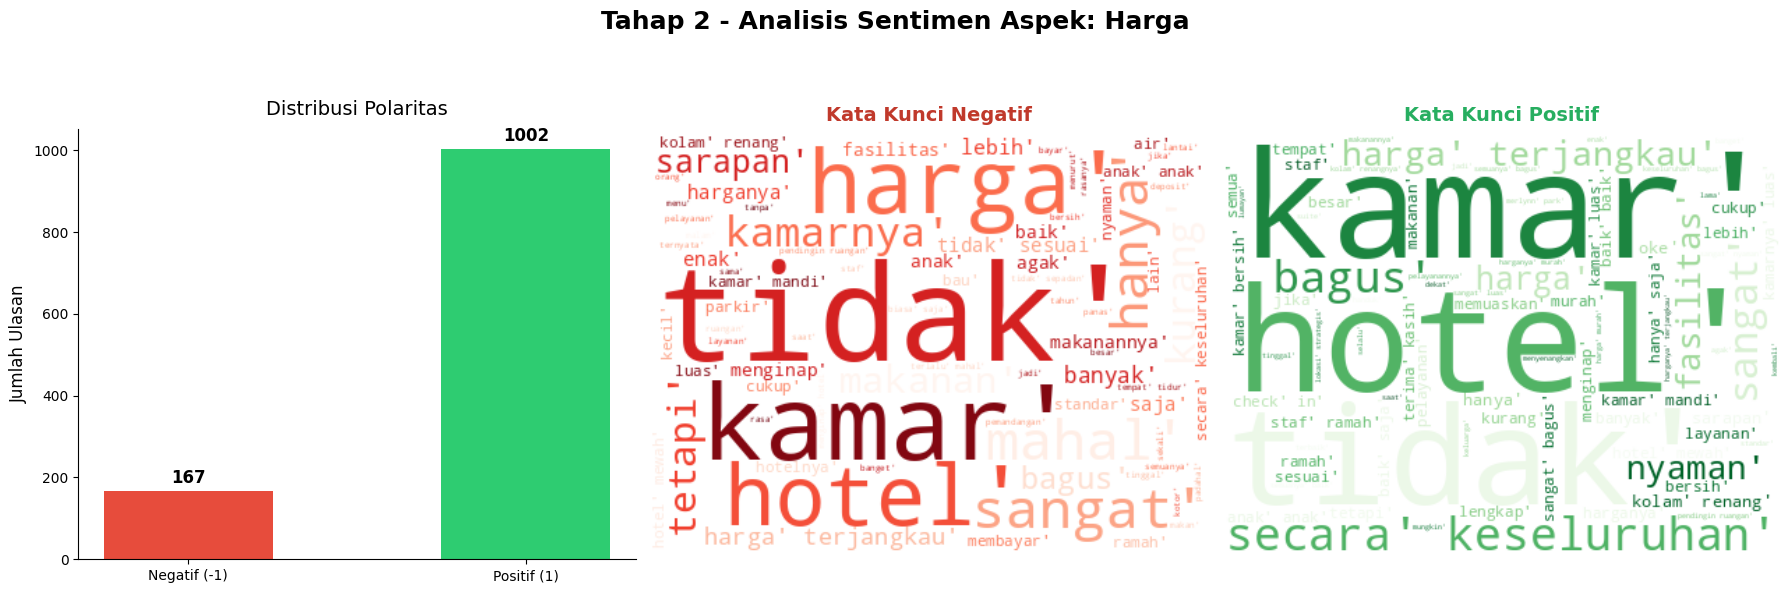

In [ ]:
# ============================================================
# EXPLORASI DATA ANALISIS - TAHAP 2 (NEGATIF vs POSITIF)
# ============================================================

for aspect in aspects:
    if aspect not in df.columns:
        continue

    df[aspect] = pd.to_numeric(df[aspect], errors='coerce')

    # Hitung Distribusi Tahap 2 (Hanya fokus pada yang dibahas: -1 dan 1)
    negatif = (df[aspect] == -1).sum()
    positif = (df[aspect] == 1).sum()

    # Lewati pembuatan plot jika aspek ini tidak punya ulasan sentimen sama sekali
    if negatif == 0 and positif == 0:
        continue

    # Extract teks ulasan khusus untuk masing-masing sentimen
    negatif_text_aspek = ' '.join(df['final_tokens'][df[aspect] == -1].astype(str).tolist())
    positif_text_aspek = ' '.join(df['final_tokens'][df[aspect] == 1].astype(str).tolist())

    # ==========================================
    # MEMBUAT PLOT TAHAP 2 (1 BARIS x 3 KOLOM)
    # ==========================================
    plt.figure(figsize=(18, 6)) # Diperlebar agar muat 3 grafik berdampingan
    plt.suptitle(f'Tahap 2 - Analisis Sentimen Aspek: {aspect}', fontsize=18, fontweight='bold', y=0.98)

    # 1. Bar Chart Distribusi Sentimen (Kiri)
    ax1 = plt.subplot(1, 3, 1)
    bars = ax1.bar(['Negatif (-1)', 'Positif (1)'], [negatif, positif], color=['#e74c3c', '#2ecc71'], width=0.5)
    ax1.set_title('Distribusi Polaritas', fontsize=14, pad=10)
    ax1.set_ylabel('Jumlah Ulasan', fontsize=12)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

    # Menambahkan angka di atas bar
    for bar in bars:
        height = bar.get_height()
        ax1.annotate(f'{height}',
                    xy=(bar.get_x() + bar.get_width() / 2, height),
                    xytext=(0, 3),
                    textcoords="offset points",
                    ha='center', va='bottom', fontweight='bold', fontsize=12)

    # 2. WordCloud Sentimen Negatif (Tengah)
    ax2 = plt.subplot(1, 3, 2)
    if len(negatif_text_aspek.strip()) > 0:
        wc_negatif = WordCloud(
            width=400, height=300,
            background_color='white',
            colormap='Reds',
            max_words=80
        ).generate(negatif_text_aspek)
        ax2.imshow(wc_negatif, interpolation='bilinear')
        ax2.set_title('Kata Kunci Negatif', fontsize=14, fontweight='bold', color='#c0392b', pad=10)
    else:
        ax2.text(0.5, 0.5, 'Tidak ada data Negatif', ha='center', va='center', fontsize=12)
    ax2.axis('off')

    # 3. WordCloud Sentimen Positif (Kanan)
    ax3 = plt.subplot(1, 3, 3)
    if len(positif_text_aspek.strip()) > 0:
        wc_positif = WordCloud(
            width=400, height=300,
            background_color='white',
            colormap='Greens',
            max_words=80
        ).generate(positif_text_aspek)
        ax3.imshow(wc_positif, interpolation='bilinear')
        ax3.set_title('Kata Kunci Positif', fontsize=14, fontweight='bold', color='#27ae60', pad=10)
    else:
        ax3.text(0.5, 0.5, 'Tidak ada data Positif', ha='center', va='center', fontsize=12)
    ax3.axis('off')

    plt.tight_layout(rect=[0, 0, 1, 0.92])
    plt.show()

In [ ]:
# Fungsi Split Tahap 2 (Negatif [0] vs Positif [1])
def split_stage2(df_src, aspek):
    subset = df_src[['text_ready', aspek]].copy()
    # Murni hanya mengambil ulasan yang membahas aspek tersebut (-1 dan 1)
    subset = subset[subset[aspek].isin([-1, 1])].dropna()
    
    if len(subset) < 20: return None
    
    X = subset['text_ready'].astype(str).values
    # Mapping T2: -1 menjadi 0 (Negatif), 1 menjadi 1 (Positif)
    y = subset[aspek].apply(lambda x: 0 if x == -1 else 1).values
    
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=(1 - TRAIN_RATIO), random_state=RANDOM_STATE, stratify=y)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=VAL_RATIO_WITHIN_REST, random_state=RANDOM_STATE, stratify=y_temp)
    return X_train, X_val, X_test, y_train, y_val, y_test

In [ ]:
print("\n" + "="*85)
print(" 📊 DISTRIBUSI DATA TAHAP 2: SENTIMEN POLARITAS")
print("    (0 = Negatif, 1 = Positif)")
print("="*85)
print(f"{'Aspek':<12} | {'Train Set':<25} | {'Val Set':<10} | {'Test Set':<10} | {'Total'}")
print("-" * 85)

for aspek in aspects:
    splitted = split_stage2(df_model, aspek)
    if splitted is None:
        print(f"{aspek:<12} | ⚠️ Data tidak cukup untuk displit")
        continue

    X_tr, X_va, X_te, y_tr, y_va, y_te = splitted
    
    # Hitung jumlah per kelas di Data Train
    c0_tr = (y_tr == 0).sum()
    c1_tr = (y_tr == 1).sum()
    
    total_aspek = len(y_tr) + len(y_va) + len(y_te)
    
    print(f"{aspek:<12} | {len(y_tr):<5} (0: {c0_tr:<4} | 1: {c1_tr:<4}) | {len(y_va):<10} | {len(y_te):<10} | {total_aspek}")
print("="*85)


 📊 DISTRIBUSI DATA TAHAP 2: SENTIMEN POLARITAS
    (0 = Negatif, 1 = Positif)
Aspek        | Train Set                 | Val Set    | Test Set   | Total
-------------------------------------------------------------------------------------
Pelayanan    | 2479  (0: 609  | 1: 1870) | 531        | 532        | 3542
Kamar        | 3140  (0: 875  | 1: 2265) | 673        | 674        | 4487
Fasilitas    | 1724  (0: 614  | 1: 1110) | 370        | 370        | 2464
Makanan      | 1862  (0: 568  | 1: 1294) | 399        | 400        | 2661
Lokasi       | 1084  (0: 79   | 1: 1005) | 232        | 233        | 1549
Suasana      | 851   (0: 218  | 1: 633 ) | 183        | 183        | 1217
Harga        | 818   (0: 117  | 1: 701 ) | 175        | 176        | 1169


In [ ]:
all_results_t2 = {}
all_histories_t2 = {}
all_predictions_t2 = {}
all_tokenizers_t2 = {}

for aspek in aspects:
    print("\n" + "=" * 60)
    print(f"🚀 TRAINING TAHAP 2 (SENTIMEN): {aspek.upper()}")
    print("=" * 60)

    splitted = split_stage2(df_model, aspek)
    if splitted is None: 
        print(f"⚠️ Aspek {aspek} dilewati karena data tidak mencukupi.")
        continue

    X_tr_text, X_va_text, X_te_text, y_tr, y_va, y_te = splitted

    # Menghitung Class Weight untuk menyeimbangkan kelas pelatihan secara otomatis
    weights = class_weight.compute_class_weight('balanced', classes=np.unique(y_tr), y=y_tr)
    class_weight_dict = dict(enumerate(weights))
    print(f"Bobot penalti kelas Tahap 2 diterapkan: {class_weight_dict}")

    # Fitting Tokenizer
    tokenizer = Tokenizer(oov_token='<OOV>')
    tokenizer.fit_on_texts(X_tr_text)
    all_tokenizers_t2[aspek] = tokenizer

    X_tr = pad_sequences(tokenizer.texts_to_sequences(X_tr_text), maxlen=panjang_maksimal, padding='post', truncating='post')
    X_va = pad_sequences(tokenizer.texts_to_sequences(X_va_text), maxlen=panjang_maksimal, padding='post', truncating='post')
    X_te = pad_sequences(tokenizer.texts_to_sequences(X_te_text), maxlen=panjang_maksimal, padding='post', truncating='post')

    # FastText Embedding Matrix
    vocab_size = len(tokenizer.word_index) + 1
    embedding_matrix = np.zeros((vocab_size, 300))
    for word, i in tokenizer.word_index.items():
        embedding_matrix[i] = ft_model.get_word_vector(word)

    model = build_model(vocab_size=vocab_size, embedding_matrix=embedding_matrix)

    callbacks = [
        EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True, verbose=1),
        ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2, min_lr=1e-5, verbose=1)
    ]

    # Proses latih menggunakan class_weight
    history = model.fit(
        X_tr, y_tr, epochs=EPOCHS, batch_size=BATCH_SIZE, validation_data=(X_va, y_va),
        class_weight=class_weight_dict, callbacks=callbacks, verbose=1
    )
    
    y_pred = np.argmax(model.predict(X_te, verbose=0), axis=1)

    # Simpan riwayat seperti kodemu
    all_histories_t2[aspek] = history.history
    all_predictions_t2[aspek] = (y_te, y_pred)
    all_results_t2[aspek] = classification_report(y_te, y_pred, target_names=['Negatif', 'Positif'], output_dict=True, zero_division=0)
    
    # Menyimpan Model & Tokenizer Tahap 1
    slug = aspect_slug(aspek)
    model.save(f'{MODEL_DIR}/t2_sentimen_{slug}.keras')
    with open(f'{TOKENIZER_DIR}/tokenizer_t2_{slug}.json', 'w', encoding='utf-8') as f:
        f.write(tokenizer.to_json())
        
    print(f"✅ [Tahap 2 - {aspek}] Selesai T2! Macro F1-Score test: {all_results_t2[aspek]['macro avg']['f1-score'] * 100:.2f}%")

print("\n" + "="*60)
print("  ARSITEKTUR MODEL BiLSTM + ATTENTION")
print("="*60)
model_preview = build_model(vocab_size, embedding_matrix)
model_preview.summary()
print("="*60 + "\n")


🚀 TRAINING TAHAP 2 (SENTIMEN): PELAYANAN
Bobot penalti kelas Tahap 2 diterapkan: {0: np.float64(2.035303776683087), 1: np.float64(0.6628342245989305)}
Epoch 1/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - accuracy: 0.5616 - loss: 0.1724 - val_accuracy: 0.8362 - val_loss: 0.0973 - learning_rate: 0.0010
Epoch 2/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8312 - loss: 0.1120 - val_accuracy: 0.8418 - val_loss: 0.0891 - learning_rate: 0.0010
Epoch 3/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8229 - loss: 0.0939 - val_accuracy: 0.8173 - val_loss: 0.0859 - learning_rate: 0.0010
Epoch 4/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8599 - loss: 0.0784 - val_accuracy: 0.8851 - val_loss: 0.0706 - learning_rate: 0.0010
Epoch 5/50
155/155 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.8653 - loss: 0.0749 - val_accuracy: 0.8606 - val_loss: 0.0956 - learning_rate: 0.0010
Epoch 6/50
153/155 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.8795 - loss: 0.0

Model: "BiLSTM_Attention_TwoStage"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_Teks (InputLayer)         │ (None, 100)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ FastText_Embedding (Embedding)  │ (None, 100, 300)       │       636,600 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Spatial_Dropout                 │ (None, 100, 300)       │             0 │
│ (SpatialDropout1D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Conv1D_Bigram (Conv1D)          │ (None, 100, 64)        │        38,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ BiLSTM (Bidirectional)          │ (None, 100, 256)       │       197,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Attention (AttentionLayer)      │ (None, 256)            │           257 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Output_Softmax (Dense)          │ (None, 2)              │           514 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 873,467 (3.33 MB)

 Trainable params: 236,867 (925.26 KB)

 Non-trainable params: 636,600 (2.43 MB)

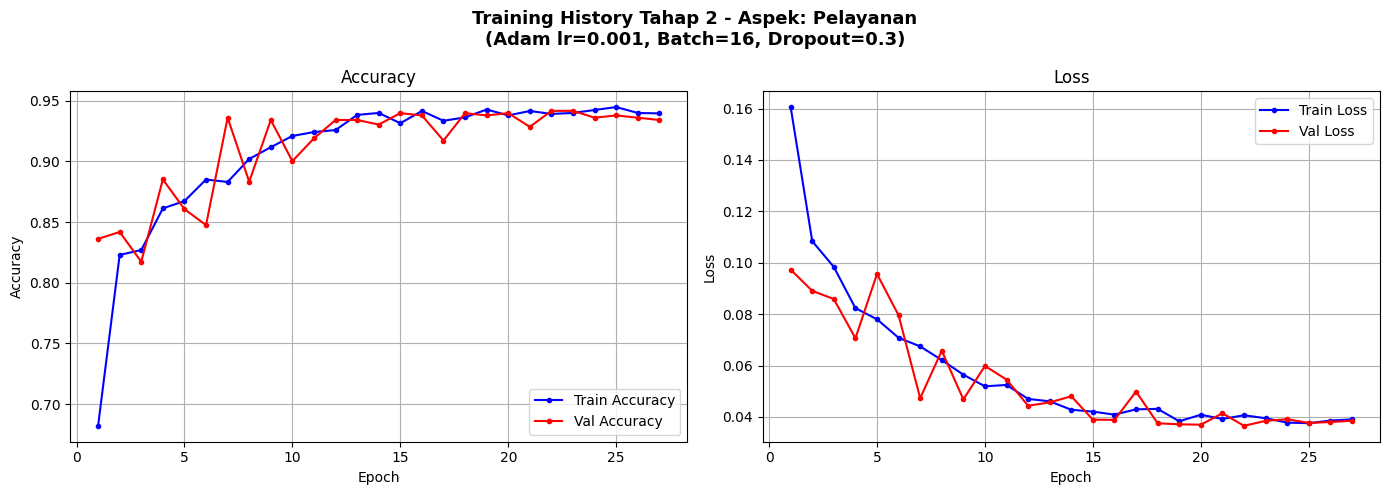

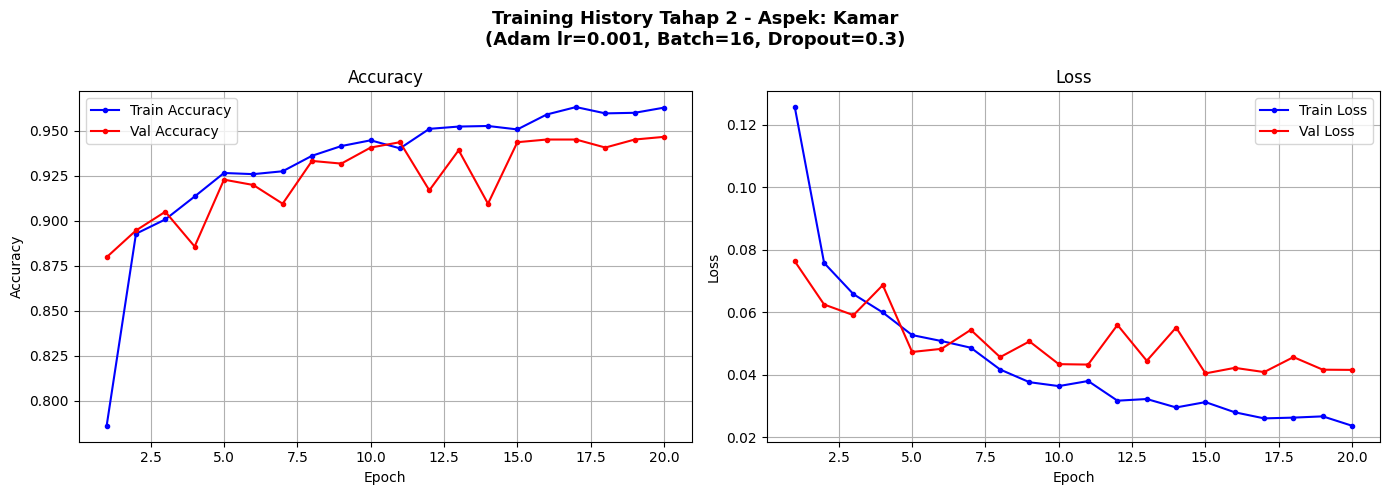

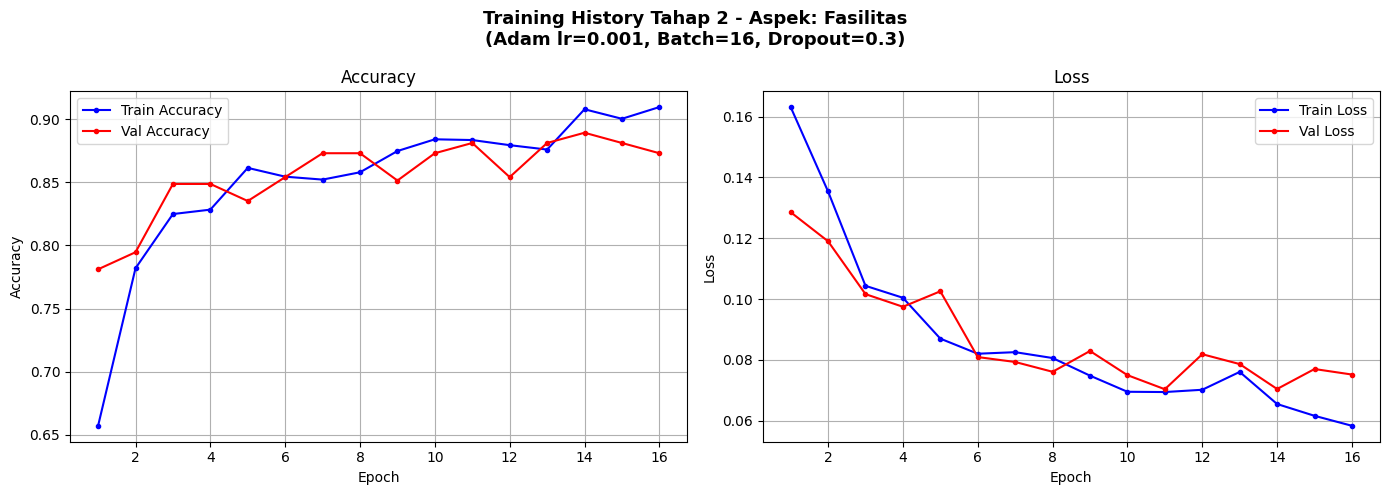

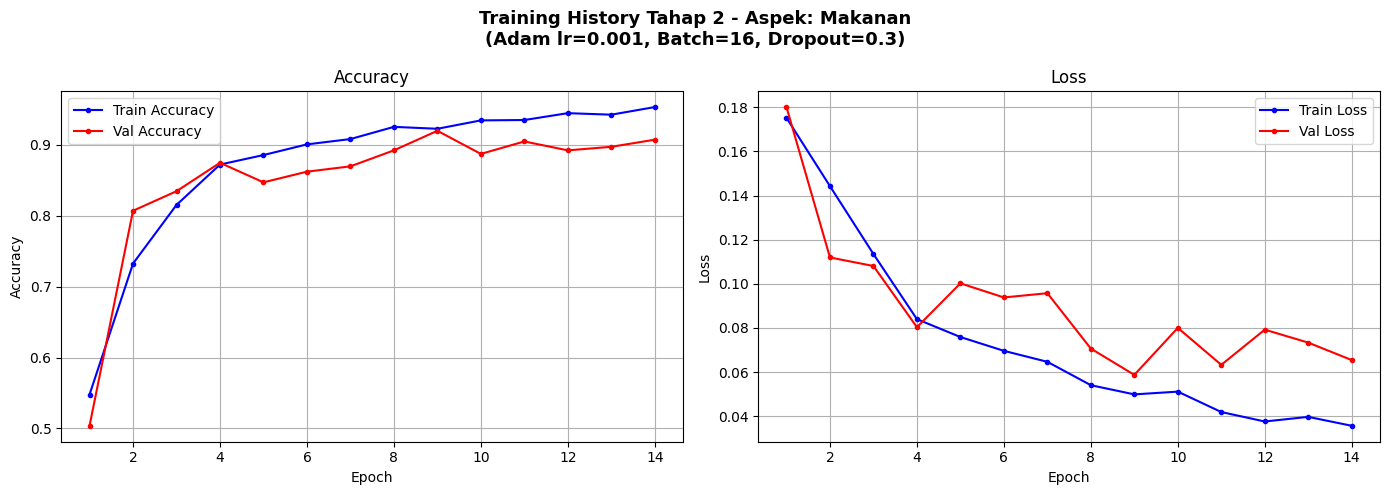

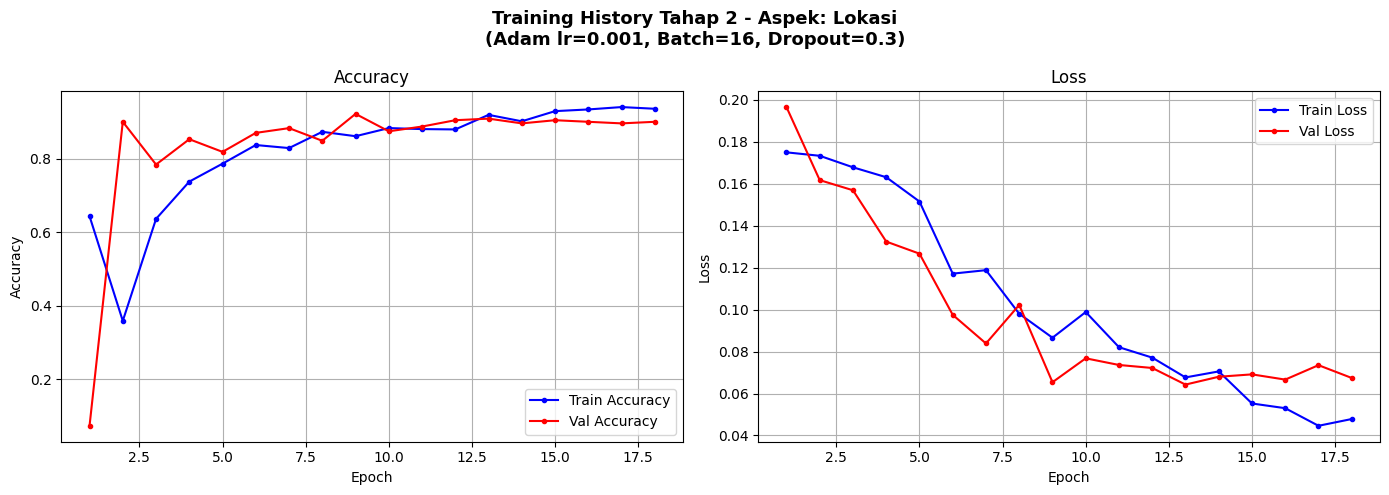

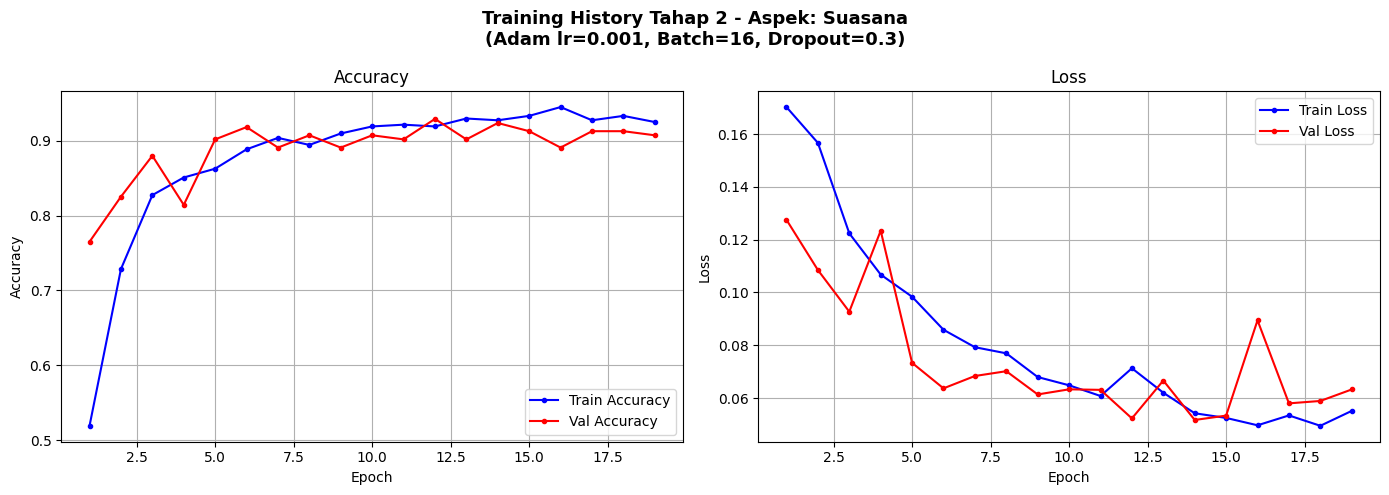

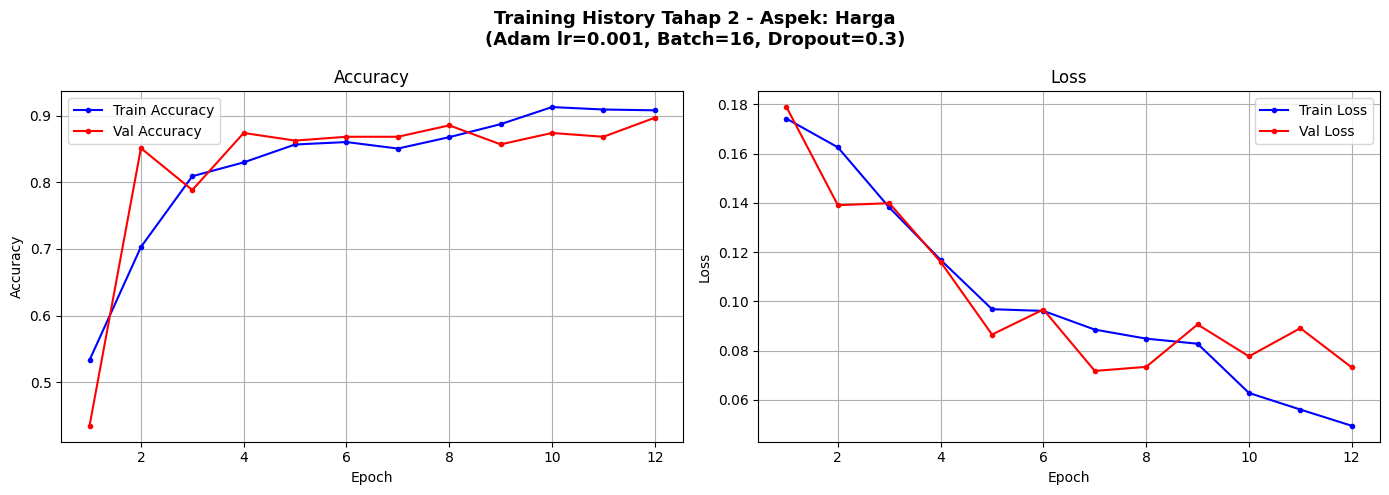

In [ ]:
def plot_history(history_dict, aspek_name, tahap_name):
    acc = history_dict['accuracy']; val_acc = history_dict['val_accuracy']
    loss = history_dict['loss']; val_loss = history_dict['val_loss']
    epochs = range(1, len(acc) + 1)

    plt.figure(figsize=(14, 5))
    plt.suptitle(f'Training History {tahap_name} - Aspek: {aspek_name}\n(Adam lr={LEARNING_RATE}, Batch={BATCH_SIZE}, Dropout={DROPOUT_RATE})', fontsize=13, fontweight='bold')
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc, 'b-o', markersize=3, label='Train Accuracy')
    plt.plot(epochs, val_acc, 'r-o', markersize=3, label='Val Accuracy')
    plt.title('Accuracy'); plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(True)

    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss, 'b-o', markersize=3, label='Train Loss')
    plt.plot(epochs, val_loss, 'r-o', markersize=3, label='Val Loss')
    plt.title('Loss'); plt.xlabel('Epoch'); plt.ylabel('Loss'); plt.legend(); plt.grid(True)
    plt.tight_layout(); plt.show()

for aspek in aspects:
    if aspek in all_histories_t2: plot_history(all_histories_t2[aspek], aspek, "Tahap 2")

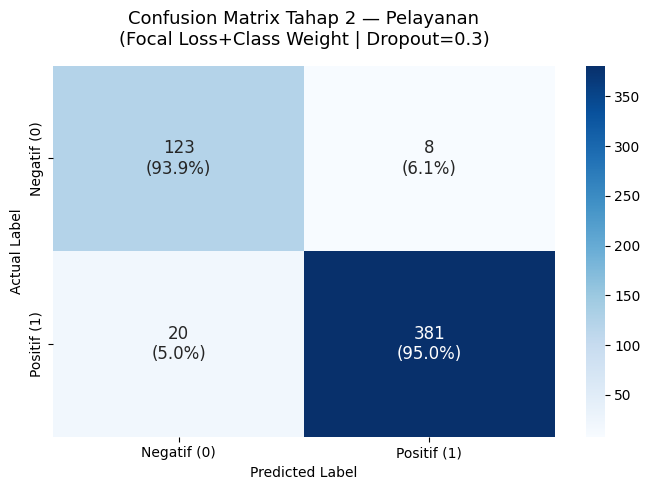

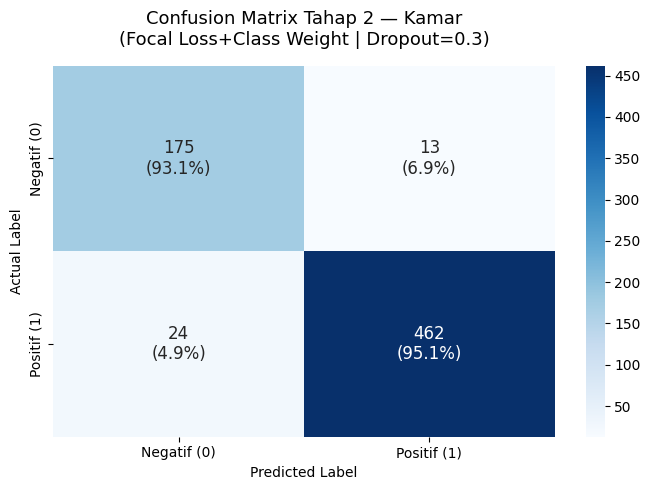

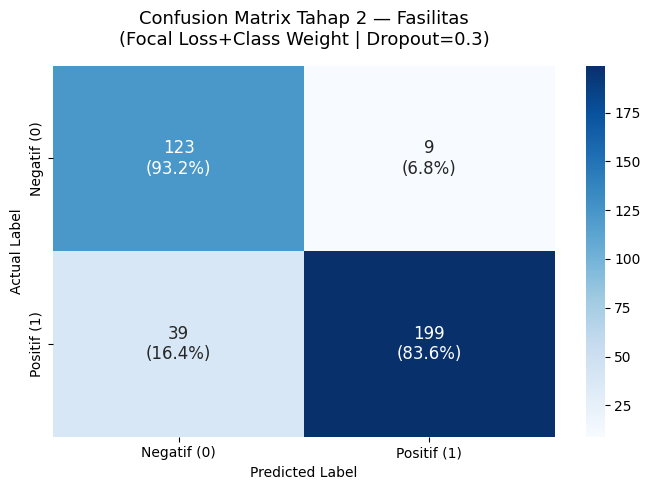

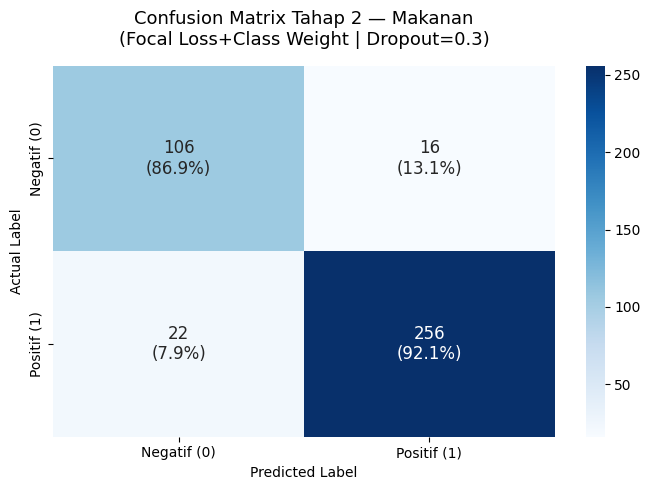

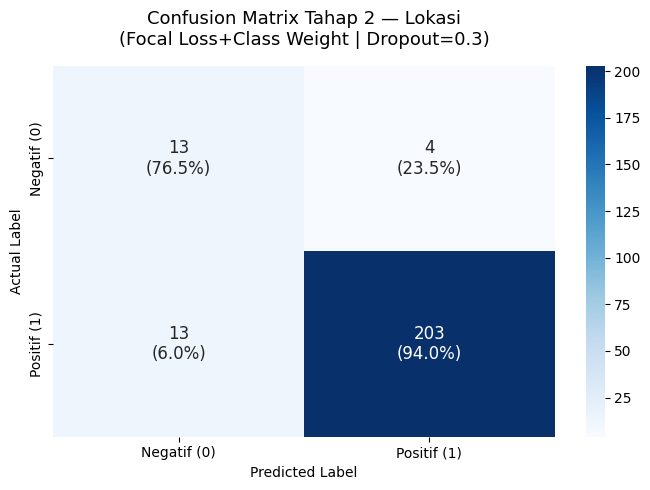

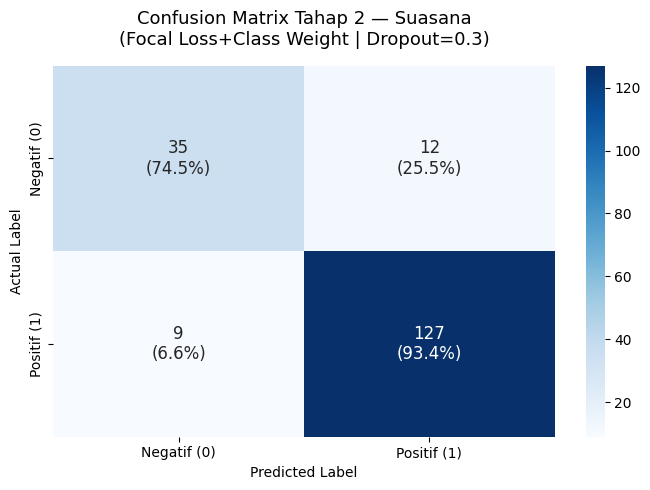

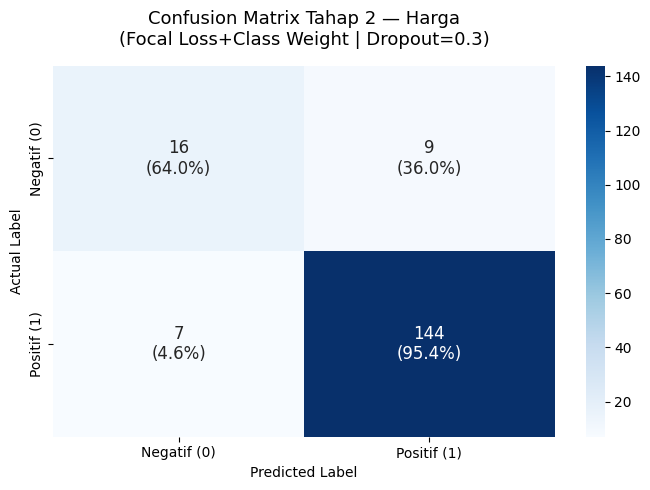

In [ ]:
def plot_confusion_matrix(y_true, y_pred, aspek_name, tahap_name, labels):
    cm = confusion_matrix(y_true, y_pred)
    with np.errstate(divide='ignore', invalid='ignore'):
        cm_percent = np.nan_to_num(cm.astype('float') / cm.sum(axis=1)[:, np.newaxis])
    annot = np.empty_like(cm).astype(str)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]): annot[i, j] = f'{cm[i,j]}\n({cm_percent[i,j]*100:.1f}%)'

    plt.figure(figsize=(7, 5))
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', xticklabels=labels, yticklabels=labels, annot_kws={"size": 12})
    plt.title(f'Confusion Matrix {tahap_name} — {aspek_name}\n(Focal Loss+Class Weight | Dropout={DROPOUT_RATE})', pad=15, fontsize=13)
    plt.ylabel('Actual Label'); plt.xlabel('Predicted Label'); plt.tight_layout(); plt.show()

for aspek in aspects:
    if aspek in all_predictions_t2:
        y_true, y_pred = all_predictions_t2[aspek]
        plot_confusion_matrix(y_true, y_pred, aspek, "Tahap 2", ['Negatif (0)', 'Positif (1)'])

In [ ]:
rows_t2 = []
for aspek in aspects:
    if aspek not in all_predictions_t2 or aspek not in all_results_t2: continue
    y_true, y_pred = all_predictions_t2[aspek]; r = all_results_t2[aspek]
    rows_t2.append({
        'Aspek': aspek,
        'Accuracy (%)': round(accuracy_score(y_true, y_pred) * 100, 2),
        'Macro Precision': round(r['macro avg']['precision'] * 100, 2),
        'Macro Recall': round(r['macro avg']['recall'] * 100, 2),
        'Macro F1 (%)': round(r['macro avg']['f1-score'] * 100, 2),
        'Weighted F1 (%)': round(r['weighted avg']['f1-score'] * 100, 2),
    })
df_summary_t2 = pd.DataFrame(rows_t2).set_index('Aspek') if rows_t2 else pd.DataFrame()

print("\n" + "=" * 70)
print("HASIL MODEL TWO-STAGE (FOCAL LOSS + CLASS WEIGHT)")
print(
    f"Hyperparameter: Adam lr={LEARNING_RATE} | "
    f"Batch={BATCH_SIZE} | Dropout={DROPOUT_RATE} | "
    f"Early Stop patience={PATIENCE}"
)
print("=" * 70)

if len(df_summary_t2) == 0:
    print("Belum ada aspek yang berhasil ditraining.")
else:
    print(df_summary_t2.to_string())
    print("-" * 70)
    print(f"Rata-rata Macro F1  : {df_summary_t2['Macro F1 (%)'].mean():.2f}%")
    print(f"Rata-rata Accuracy  : {df_summary_t2['Accuracy (%)'].mean():.2f}%")
print("=" * 70)


HASIL MODEL TWO-STAGE (FOCAL LOSS + CLASS WEIGHT)
Hyperparameter: Adam lr=0.001 | Batch=16 | Dropout=0.3 | Early Stop patience=5
           Accuracy (%)  Macro Precision  Macro Recall  Macro F1 (%)  Weighted F1 (%)
Aspek                                                                                
Pelayanan         94.74            91.98         94.45         93.12            94.81
Kamar             94.51            92.60         94.07         93.29            94.56
Fasilitas         87.03            85.80         88.40         86.46            87.25
Makanan           90.50            88.47         89.49         88.95            90.56
Lokasi            92.70            74.03         85.23         78.22            93.39
Suasana           88.52            85.46         83.93         84.64            88.40
Harga             90.91            81.84         79.68         80.70            90.75
----------------------------------------------------------------------
Rata-rata Macro F1  : 86.

In [42]:
from tensorflow.keras.models import load_model
from tensorflow.keras.preprocessing.text import tokenizer_from_json

def aspect_slug(aspek):
    return aspek.lower().replace(' ', '_')

print("Memuat model + tokenizer per aspek (Two-Stage)...")
loaded_models_t1 = {}
loaded_tokenizers_t1 = {}
loaded_models_t2 = {}
loaded_tokenizers_t2 = {}

for aspek in aspects:
    slug = aspect_slug(aspek)
    
    # Path File Tahap 1 (Deteksi)
    model_file_t1 = f'{MODEL_DIR}/t1_deteksi_{slug}.keras'
    tokenizer_file_t1 = f'{TOKENIZER_DIR}/tokenizer_t1_{slug}.json'
    
    # Path File Tahap 2 (Sentimen)
    model_file_t2 = f'{MODEL_DIR}/t2_sentimen_{slug}.keras'
    tokenizer_file_t2 = f'{TOKENIZER_DIR}/tokenizer_t2_{slug}.json'

    # Load Tahap 1 (Wajib sertakan custom_objects agar Keras tidak error)
    if os.path.exists(model_file_t1) and os.path.exists(tokenizer_file_t1):
        loaded_models_t1[aspek] = load_model(
            model_file_t1,
            custom_objects={
                'AttentionLayer': AttentionLayer,
                'CustomSparseCategoricalFocalCrossentropy': CustomSparseCategoricalFocalCrossentropy
            }
        )
        with open(tokenizer_file_t1, 'r', encoding='utf-8') as f:
            loaded_tokenizers_t1[aspek] = tokenizer_from_json(f.read())

    # Load Tahap 2
    if os.path.exists(model_file_t2) and os.path.exists(tokenizer_file_t2):
        loaded_models_t2[aspek] = load_model(
            model_file_t2,
            custom_objects={
                'AttentionLayer': AttentionLayer,
                'CustomSparseCategoricalFocalCrossentropy': CustomSparseCategoricalFocalCrossentropy
            }
        )
        with open(tokenizer_file_t2, 'r', encoding='utf-8') as f:
            loaded_tokenizers_t2[aspek] = tokenizer_from_json(f.read())

print(f"✅ Tahap 1 Berhasil Dimuat: {len(loaded_models_t1)} aspek")
print(f"✅ Tahap 2 Berhasil Dimuat: {len(loaded_models_t2)} aspek")


# Pipeline preprocessing inferensi (identik dengan milikmu)
def preprocess_input(teks):
    teks = case_folding(teks)
    teks = text_cleaning(teks)
    tokens = tokenization(teks)
    tokens = normalization(tokens)
    tokens = stopword_removal(tokens)
    return join_tokens(tokens)


def prediksi_ulasan(teks_asli, tampilkan_proba=False):
    if len(loaded_models_t1) == 0:
        print("Belum ada model yang bisa dipakai. Jalankan training terlebih dahulu.")
        return

    teks_bersih = preprocess_input(teks_asli)

    print("\n" + "=" * 65)
    print("HASIL PREDIKSI SENTIMEN PER ASPEK (TWO-STAGE)")
    print("=" * 65)
    
    for aspek in loaded_models_t1:
        # ── TAHAP 1: DETEKSI KEBERADAAN ASPEK ──
        tokenizer_t1 = loaded_tokenizers_t1[aspek]
        seq_t1 = tokenizer_t1.texts_to_sequences([teks_bersih])
        pad_t1 = pad_sequences(seq_t1, maxlen=panjang_maksimal, padding='post', truncating='post')
        
        prob_t1 = loaded_models_t1[aspek].predict(pad_t1, verbose=0)[0]
        label_t1 = int(np.argmax(prob_t1)) # 0 = Tidak Dibahas, 1 = Dibahas
        
        if label_t1 == 0:
            label_str = "tidak dibahas"
            proba_str = f"[T1_tdk={prob_t1[0]:.2f} | T1_ada={prob_t1[1]:.2f}]"
        else:
            # ── TAHAP 2: EVALUASI SENTIMEN POLARITAS (Hanya jika T1 = Dibahas) ──
            if aspek in loaded_models_t2:
                tokenizer_t2 = loaded_tokenizers_t2[aspek]
                seq_t2 = tokenizer_t2.texts_to_sequences([teks_bersih])
                pad_t2 = pad_sequences(seq_t2, maxlen=panjang_maksimal, padding='post', truncating='post')
                
                prob_t2 = loaded_models_t2[aspek].predict(pad_t2, verbose=0)[0]
                label_t2 = int(np.argmax(prob_t2)) # 0 = Negatif, 1 = Positif
                
                label_str = "negatif" if label_t2 == 0 else "positif"
                proba_str = f"[T2_neg={prob_t2[0]:.2f} | T2_pos={prob_t2[1]:.2f}]"
            else:
                label_str = "dibahas (model T2 N/A)"
                proba_str = "[N/A]"

        # Cetak Hasil Sesuai Gaya Kodemu
        if tampilkan_proba:
            print(f"{aspek:<12}: {label_str:<14} {proba_str}")
        else:
            print(f"{aspek:<12}: {label_str}")

    print("=" * 65)
    print(f"Teks: {teks_asli[:100]}...")
    print("=" * 65)


# Contoh Eksekusi Pengujian Kalimat Baru
contoh_ulasan = [
     "stafnya cuek banget, kamar bau rokok dan makanannya asin. kolam renangnya bersih",
]

for ulasan in contoh_ulasan:
    prediksi_ulasan(ulasan, tampilkan_proba=True)

Memuat model + tokenizer per aspek (Two-Stage)...
✅ Tahap 1 Berhasil Dimuat: 7 aspek
✅ Tahap 2 Berhasil Dimuat: 7 aspek

HASIL PREDIKSI SENTIMEN PER ASPEK (TWO-STAGE)
Pelayanan   : negatif        [T2_neg=0.62 | T2_pos=0.38]
Kamar       : negatif        [T2_neg=0.81 | T2_pos=0.19]
Fasilitas   : negatif        [T2_neg=0.61 | T2_pos=0.39]
Makanan     : negatif        [T2_neg=0.54 | T2_pos=0.46]
Lokasi      : tidak dibahas  [T1_tdk=0.85 | T1_ada=0.15]
Suasana     : tidak dibahas  [T1_tdk=0.60 | T1_ada=0.40]
Harga       : tidak dibahas  [T1_tdk=0.89 | T1_ada=0.11]
Teks: stafnya cuek banget, kamar bau rokok dan makanannya asin. kolam renangnya bersih...


In [ ]:
import shutil, os

# Compress semua model + tokenizer
shutil.make_archive('sentihotel_models', 'zip', '.', 'saved_models')
shutil.make_archive('sentihotel_tokenizers', 'zip', '.', 'saved_tokenizers')

# Cek file
print("File siap diunduh:")
for f in ['sentihotel_models.zip', 'sentihotel_tokenizers.zip']:
    size = os.path.getsize(f) / (1024*1024)
    print(f"  {f}: {size:.1f} MB")

File siap diunduh:
  sentihotel_models.zip: 92.0 MB
  sentihotel_tokenizers.zip: 1.3 MB
